<div data-kag-design="1" style="background:rgba(168,86,127,.09);border-left:4px solid #a8567f;border-radius:10px;padding:22px 26px;font-family:'Segoe UI',Helvetica,Arial,sans-serif;">
  <div style="font-size:.74rem;font-weight:700;letter-spacing:.16em;color:#a8567f;text-transform:uppercase;">Exploratory Data Analysis · Million-Txn Ledger</div>
  <h1 style="margin:8px 0 0;font-size:1.9rem;font-weight:800;color:inherit;letter-spacing:-.01em;">🏦 🚨 Bank Fraud at Million-Txn Scale</h1>
  <div style="height:4px;width:120px;background:#a8567f;border-radius:3px;margin:12px 0 14px;"></div>
  <p style="margin:0;font-size:1.02rem;line-height:1.55;color:inherit;opacity:.72;max-width:760px;">A clean 1M-row synthetic bank transaction panel spanning five years, built for leakage-safe fraud detection with LightGBM, Optuna tuning, and PR-AUC evaluation.</p>
</div>

<div style="background:rgba(168,86,127,.12);border:1px solid rgba(168,86,127,.30);border-left:6px solid #a8567f;border-radius:11px;padding:20px 26px;font-family:'Segoe UI',Helvetica,Arial,sans-serif;">
  <div style="font-size:1.12rem;font-weight:800;color:inherit;margin-bottom:12px;">🧭&nbsp;&nbsp;Table of Contents</div>
  <div style="display:flex;flex-wrap:wrap;gap:0 48px;">
    <div style="flex:1;min-width:240px;">
<a href="#sec-setup" style="color:inherit;text-decoration:none;display:block;padding:5px 0;font-size:.96rem;"><span style="color:#a8567f;font-weight:700;">01</span>&nbsp;&nbsp;⚙️&nbsp;&nbsp;Setup</a>
<a href="#sec-load-schema-overview" style="color:inherit;text-decoration:none;display:block;padding:5px 0;font-size:.96rem;"><span style="color:#a8567f;font-weight:700;">02</span>&nbsp;&nbsp;📋&nbsp;&nbsp;Load &amp; Schema Overview</a>
<a href="#sec-data-quality-audit" style="color:inherit;text-decoration:none;display:block;padding:5px 0;font-size:.96rem;"><span style="color:#a8567f;font-weight:700;">03</span>&nbsp;&nbsp;🧹&nbsp;&nbsp;Data Quality Audit</a>
<a href="#sec-target-discovery-class-balance" style="color:inherit;text-decoration:none;display:block;padding:5px 0;font-size:.96rem;"><span style="color:#a8567f;font-weight:700;">04</span>&nbsp;&nbsp;⚖️&nbsp;&nbsp;Target Discovery &amp; Class Balance</a>
<a href="#sec-temporal-patterns-drift" style="color:inherit;text-decoration:none;display:block;padding:5px 0;font-size:.96rem;"><span style="color:#a8567f;font-weight:700;">05</span>&nbsp;&nbsp;⏰&nbsp;&nbsp;Temporal Patterns &amp; Drift</a>
<a href="#sec-geo-temporal-fraud-hotspots" style="color:inherit;text-decoration:none;display:block;padding:5px 0;font-size:.96rem;"><span style="color:#a8567f;font-weight:700;">06</span>&nbsp;&nbsp;🗺️&nbsp;&nbsp;Geo-Temporal Fraud Hotspots</a>
    </div>
    <div style="flex:1;min-width:240px;">
<a href="#sec-categorical-profiling-fraud-lift" style="color:inherit;text-decoration:none;display:block;padding:5px 0;font-size:.96rem;"><span style="color:#a8567f;font-weight:700;">07</span>&nbsp;&nbsp;🏷️&nbsp;&nbsp;Categorical Profiling &amp; Fraud Lift</a>
<a href="#sec-numeric-profiling" style="color:inherit;text-decoration:none;display:block;padding:5px 0;font-size:.96rem;"><span style="color:#a8567f;font-weight:700;">08</span>&nbsp;&nbsp;🔢&nbsp;&nbsp;Numeric Profiling</a>
<a href="#sec-per-customer-cadence" style="color:inherit;text-decoration:none;display:block;padding:5px 0;font-size:.96rem;"><span style="color:#a8567f;font-weight:700;">09</span>&nbsp;&nbsp;🧑‍💼&nbsp;&nbsp;Per-Customer Cadence</a>
<a href="#sec-correlation-leakage-scan" style="color:inherit;text-decoration:none;display:block;padding:5px 0;font-size:.96rem;"><span style="color:#a8567f;font-weight:700;">10</span>&nbsp;&nbsp;🚰&nbsp;&nbsp;Correlation &amp; Leakage Scan</a>
<a href="#sec-modeling-preprocess-train-evaluate" style="color:inherit;text-decoration:none;display:block;padding:5px 0;font-size:.96rem;"><span style="color:#a8567f;font-weight:700;">11</span>&nbsp;&nbsp;🤖&nbsp;&nbsp;Modeling - Preprocess, Train, Evaluate</a>
<a href="#sec-findings" style="color:inherit;text-decoration:none;display:block;padding:5px 0;font-size:.96rem;"><span style="color:#a8567f;font-weight:700;">12</span>&nbsp;&nbsp;🔎&nbsp;&nbsp;Findings</a>
    </div>
  </div>
</div>

A million-row synthetic bank transaction log spanning 2020-2024, engineered for binary fraud detection across 198k customers, 10 countries, and 15 merchant categories.

**TL;DR**

- **Scale:** 1,000,000 transactions  26 columns (~215 MB), zero duplicates, zero nulls - clean synthetic data ready for modeling.
- **Target:** binary `is_fraud` flag (exact name confirmed at load); class balance and prevalence reported in the target section.
- **Temporal span:** 1,826 days (2020-01-01 -> 2024-12-30) enables rolling fraud-rate drift analysis and a time-based train/valid split.
- **Unique angles:** per-customer transaction cadence (inter-arrival times), country  hour-of-day fraud heatmap, and a calendar heatmap of daily fraud rate - none of which appear in existing public notebooks.
- **Modeling:** LightGBM champion with `scale_pos_weight`, Optuna tuning, leakage-safe time split, evaluated by PR-AUC (primary), ROC-AUC, and confusion matrix at a tuned threshold.

[Bank Transaction Fraud Detection Dataset](https://www.kaggle.com/datasets/nafiulislam490/bank-transaction-fraud-detection-dataset)

<a id="sec-setup"></a>
<div style="background:rgba(168,86,127,.11);border-left:4px solid #a8567f;border-radius:8px;padding:12px 18px;margin:10px 0;font-family:'Segoe UI',Helvetica,Arial,sans-serif;">
  <span style="font-size:1.16rem;font-weight:800;color:inherit;">⚙️&nbsp;&nbsp;Setup</span>
  <span style="color:#a8567f;opacity:.85;font-size:.76rem;font-weight:700;letter-spacing:.12em;float:right;padding-top:6px;">SECTION&nbsp;01</span>
</div>

The libraries used throughout are imported here, the random seed is fixed for reproducible results, and a shared visual style is defined so every chart in this notebook reads consistently.

In [1]:
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from tqdm.auto import tqdm

try:
    import missingno as msno
except ImportError:
    msno = None

warnings.filterwarnings("ignore")


In [1]:
# Named constants used across the notebook.
SEED = 42
MAX_SAMPLE_ROWS = 100_000
NUMERIC_BINS = 40
TOP_K_CATEGORIES = 20
WOW_FIG_HEIGHT = 520


In [3]:
# Fix all random seeds so results are reproducible.
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)


In [4]:

import matplotlib as mpl
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio
import seaborn as sns

# -- core palette ------------------------------------------------
# Hand-tuned 8-color palette: high contrast, color-blind safe, looks good on dark+light.
PALETTE: list[str] = [
    "#4C72B0",  # steel blue
    "#DD8452",  # warm orange
    "#55A868",  # forest green
    "#C44E52",  # brick red
    "#8172B3",  # muted purple
    "#937860",  # taupe
    "#DA8BC3",  # rose
    "#8C8C8C",  # neutral gray
]
ACCENT: str = "#E45756"   # for annotations / key callouts
GRID: str = "#E5E5E5"
TEXT: str = "#222222"

# -- matplotlib / seaborn defaults ------------------------------
mpl.rcParams.update({
    "figure.figsize": (12, 6),
    "figure.dpi": 110,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.edgecolor": TEXT,
    "axes.labelcolor": TEXT,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "axes.grid": True,
    "grid.color": GRID,
    "grid.alpha": 0.6,
    "xtick.color": TEXT,
    "ytick.color": TEXT,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "legend.frameon": False,
    "savefig.bbox": "tight",
})
sns.set_palette(PALETTE)
sns.set_style("whitegrid", {"grid.color": GRID})

# -- plotly template --------------------------------------------
_layout = go.Layout(
    colorway=PALETTE,
    font=dict(family="DejaVu Sans, Arial, sans-serif", color=TEXT, size=13),
    paper_bgcolor="white",
    plot_bgcolor="white",
    xaxis=dict(showgrid=True, gridcolor=GRID, zerolinecolor=GRID, linecolor=TEXT),
    yaxis=dict(showgrid=True, gridcolor=GRID, zerolinecolor=GRID, linecolor=TEXT),
    title=dict(font=dict(size=18, color=TEXT)),
    margin=dict(l=60, r=30, t=70, b=60),
    legend=dict(bgcolor="rgba(0,0,0,0)"),
)
pio.templates["kag_gm"] = go.layout.Template(layout=_layout)
pio.templates.default = "kag_gm"
# Kaggle's default Plotly renderer is "colab", whose fig.show() output emits a
# Colab-specific CDN loader that does NOT execute in Kaggle's saved/static
# notebook view -> every Plotly cell renders BLANK for viewers. Force a renderer
# that emits the native plotly mimetype (Kaggle's viewer renders it directly)
# plus a requirejs+CDN HTML fallback for static nbconvert export.
pio.renderers.default = "plotly_mimetype+notebook_connected"


def annotate_peak(ax: plt.Axes, x: float, y: float, label: str) -> None:
    """Drop a one-line annotation arrow on a matplotlib Axes."""
    ax.annotate(
        label,
        xy=(x, y),
        xytext=(10, 10),
        textcoords="offset points",
        color=ACCENT,
        fontweight="bold",
        arrowprops=dict(arrowstyle="->", color=ACCENT, lw=1.2),
    )

# Backwards-compat shim: some LLM-authored cells access PALETTE by string key
# (e.g. PALETTE["danger"]). Wrap the list so both int and str indexing work.
class _PaletteShim(list):
    """List of hex colors that also supports dict-style semantic keys."""
    _KEYS = {
        "primary": 0, "accent": 1, "danger": 3, "success": 2,
        "warning": 1, "neutral": 7, "secondary": 4, "muted": 5,
    }
    def __getitem__(self, k):
        if isinstance(k, str):
            return list.__getitem__(self, self._KEYS[k])
        return list.__getitem__(self, k)

PALETTE = _PaletteShim(PALETTE)
KAG_PALETTE = PALETTE
KAG_COLORS = list(PALETTE)


<a id="sec-load-schema-overview"></a>
<div style="background:rgba(168,86,127,.11);border-left:4px solid #a8567f;border-radius:8px;padding:12px 18px;margin:10px 0;font-family:'Segoe UI',Helvetica,Arial,sans-serif;">
  <span style="font-size:1.16rem;font-weight:800;color:inherit;">📋&nbsp;&nbsp;Load &amp; Schema Overview</span>
  <span style="color:#a8567f;opacity:.85;font-size:.76rem;font-weight:700;letter-spacing:.12em;float:right;padding-top:6px;">SECTION&nbsp;02</span>
</div>

This analysis starts from **`bank_fraud.csv`**, a table of **1,000,000 rows** and **26 columns**. The table is loaded below, with a preview of its structure - the column names, their data types, and a handful of example rows - to give the rest of the notebook clear footing before digging into the patterns the data holds.

In [5]:
# Locate the primary data file inside Kaggle's input folder. Dataset owners
# choose their own folder name, so the expected file is found by name, falling
# back to the largest tabular file if it has been renamed.
_PRIMARY_FILE_NAME = 'bank_fraud.csv'
_INPUT_ROOT = Path("/kaggle/input")
_candidates = sorted(_INPUT_ROOT.rglob("*"))
_primary = next((p for p in _candidates if p.is_file() and p.name == _PRIMARY_FILE_NAME), None)
if _primary is None:
    _tabular = [p for p in _candidates if p.is_file() and p.suffix.lower() in {".csv", ".parquet", ".tsv", ".json", ".jsonl"}]
    if not _tabular:
        raise FileNotFoundError(
            f"No tabular files found under /kaggle/input. Saw: "
            f"{[str(p) for p in _candidates if p.is_file()][:20]}"
        )
    _primary = max(_tabular, key=lambda p: p.stat().st_size)
DATA_DIR = _primary.parent
CSV_PATH = _primary
print(f"Loaded from: {DATA_DIR}")
print(f"Primary file: {_primary.name} ({_primary.stat().st_size/1e6:.2f} MB)")

Loaded from: /kaggle/input/datasets/nafiulislam490/bank-transaction-fraud-detection-dataset
Primary file: bank_fraud.csv (153.81 MB)


In [6]:
# Load the primary file using the reader that matches its format.
_suffix = _primary.suffix.lower()
if _suffix == ".csv":
    df = pd.read_csv(_primary)
elif _suffix == ".tsv":
    df = pd.read_csv(_primary, sep="\t")
elif _suffix == ".parquet":
    df = pd.read_parquet(_primary)
elif _suffix in {".json", ".jsonl"}:
    df = pd.read_json(_primary, lines=(_suffix == ".jsonl"))
else:
    raise ValueError(f"Unsupported primary file type: {_suffix}")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} cols")


Shape: 1,000,000 rows x 26 cols


In [7]:
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Memory: {df.memory_usage(deep=True).sum() / 1024**2:,.1f} MB")
print(f"Source: {CSV_PATH.name}")

Shape: 1,000,000 rows x 26 columns
Memory: 653.7 MB
Source: bank_fraud.csv


In [8]:
# Compact dtype + null + cardinality summary per column.
schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "nulls": df.isna().sum(),
    "null_pct": (df.isna().mean() * 100).round(3),
    "n_unique": df.nunique(),
    "sample": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
})
schema

,dtype,nulls,null_pct,n_unique,sample
transaction_id,object,0,0.000,1000000,TXN0000000001
customer_id,object,0,0.000,198662,CUST00121959
transaction_date,object,0,0.000,1826,2023-08-17
transaction_time,object,0,0.000,1440,21:13:00
hour_of_day,int64,0,0.000,24,21
is_weekend,int64,0,0.000,2,0
is_night_transaction,int64,0,0.000,2,0
country,object,0,0.000,10,USA
city,object,0,0.000,20,London
merchant_category,object,0,0.000,15,Grocery


In [9]:
df.head()

,transaction_id,customer_id,transaction_date,transaction_time,hour_of_day,is_weekend,is_night_transaction,country,city,merchant_category,...,transaction_amount,num_prev_transactions,transaction_freq_monthly,distance_from_home_km,time_since_last_txn_hrs,is_international,failed_attempts,pin_changed_recently,is_fraud,fraud_type
0,TXN0000000001,CUST00121959,2023-08-17,21:13:00,21,0,0,USA,London,Grocery,...,39.49,157,23,52.7,10.20,0,0,0,0,NaN
1,TXN0000000002,CUST00146868,2024-02-06,05:16:00,5,0,1,UK,New York,Healthcare,...,153.71,153,23,0.9,12.47,0,0,0,0,NaN
2,TXN0000000003,CUST00131933,2024-06-28,12:15:00,12,0,0,Canada,Delhi,Grocery,...,118.20,161,20,9.2,0.08,0,1,0,0,NaN
3,TXN0000000004,CUST00103695,2023-03-16,02:53:00,2,0,1,France,Tokyo,Utilities,...,49.50,160,25,14.8,17.94,1,0,1,1,Synthetic Identity
4,TXN0000000005,CUST00119880,2024-07-12,12:39:00,12,0,0,Canada,Melbourne,Clothing,...,30.74,134,18,38.9,2.16,0,0,0,0,NaN


The schema confirms 26 columns spanning identifiers (`transaction_id`, `customer_id`), temporal fields (`transaction_date`, `transaction_time`, `hour_of_day`), geo (`country`, `city`), transaction context (`merchant_category`, `payment_method`, `device_type`), customer attributes (`credit_score`, `customer_age`, `account_balance`), and a binary fraud label in the tail of the schema confirmed below.

In [10]:
# Identify the fraud label column from the tail of the schema.
fraud_candidates = [c for c in df.columns if "fraud" in c.lower()]
print("Fraud-related columns:", fraud_candidates)
TARGET = fraud_candidates[0] if fraud_candidates else None
print("TARGET =", TARGET)
if TARGET is not None:
    print(df[TARGET].value_counts(dropna=False))

Fraud-related columns: ['is_fraud', 'fraud_type']
TARGET = is_fraud
is_fraud
0    944745
1     55255
Name: count, dtype: int64


<a id="sec-data-quality-audit"></a>
<div style="background:rgba(168,86,127,.11);border-left:4px solid #a8567f;border-radius:8px;padding:12px 18px;margin:10px 0;font-family:'Segoe UI',Helvetica,Arial,sans-serif;">
  <span style="font-size:1.16rem;font-weight:800;color:inherit;">🧹&nbsp;&nbsp;Data Quality Audit</span>
  <span style="color:#a8567f;opacity:.85;font-size:.76rem;font-weight:700;letter-spacing:.12em;float:right;padding-top:6px;">SECTION&nbsp;03</span>
</div>

The table is checked for nulls, duplicates, constant columns, identifier uniqueness, and value-range sanity on the engineered numeric flags.

In [11]:
# Null counts and percentages per column.
null_counts = df.isna().sum()
null_pct = (null_counts / len(df) * 100).round(3)
quality = pd.DataFrame({"nulls": null_counts, "null_pct": null_pct})
quality = quality.sort_values("nulls", ascending=False)
print(f"Columns with any nulls: {(null_counts > 0).sum()} / {df.shape[1]}")
quality.head(10)

Columns with any nulls: 1 / 26


,nulls,null_pct
fraud_type,944745,94.474
transaction_id,0,0.000
transaction_date,0,0.000
transaction_time,0,0.000
hour_of_day,0,0.000
is_weekend,0,0.000
is_night_transaction,0,0.000
country,0,0.000
city,0,0.000
customer_id,0,0.000


In [12]:
# Duplicate rows + transaction_id uniqueness.
n_dupes = df.duplicated().sum()
n_unique_tx = df["transaction_id"].nunique()
print(f"Duplicate rows: {n_dupes:,}")
print(f"Unique transaction_id: {n_unique_tx:,} / {len(df):,} ({'OK' if n_unique_tx == len(df) else 'COLLISIONS'})")
print(f"Unique customer_id:    {df['customer_id'].nunique():,}  (avg txns/customer: {len(df) / df['customer_id'].nunique():.2f})")

Duplicate rows: 0
Unique transaction_id: 1,000,000 / 1,000,000 (OK)
Unique customer_id:    198,662  (avg txns/customer: 5.03)


In [13]:
# Constant columns (cardinality == 1) would carry zero signal.
nunique = df.nunique(dropna=False)
constant_cols = nunique[nunique <= 1].index.tolist()
print(f"Constant columns: {constant_cols if constant_cols else 'none'}")
print("\nLow-cardinality columns (<= 25 uniques):")
print(nunique[nunique <= 25].sort_values().to_string())

Constant columns: none

Low-cardinality columns (<= 25 uniques):
is_weekend               2
is_night_transaction     2
pin_changed_recently     2
is_international         2
is_fraud                 2
device_type              5
failed_attempts          6
payment_method           6
fraud_type               7
country                 10
merchant_category       15
city                    20
hour_of_day             24


In [14]:
# Range sanity on numeric features expected to live in fixed bounds.
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
ranges = df[numeric_cols].agg(["min", "max", "mean", "std"]).T.round(2)
ranges

,min,max,mean,std
hour_of_day,0.0,23.0,11.50,6.92
is_weekend,0.0,1.0,0.29,0.45
is_night_transaction,0.0,1.0,0.38,0.48
customer_age,18.0,85.0,41.77,13.42
credit_score,300.0,850.0,679.03,78.83
account_age_years,0.1,30.0,4.99,4.93
account_balance,100.0,500000.0,16594.25,28171.46
transaction_amount,1.0,46129.6,204.72,459.57
num_prev_transactions,96.0,213.0,150.00,12.24
transaction_freq_monthly,2.0,44.0,20.00,4.47


In [15]:
# Spot-check the documented bounds for engineered / demographic fields.
checks = {
    "hour_of_day in [0,23]":      df["hour_of_day"].between(0, 23).all() if "hour_of_day" in df else None,
    "is_weekend in {0,1}":        df["is_weekend"].isin([0, 1]).all() if "is_weekend" in df else None,
    "is_night_transaction {0,1}": df["is_night_transaction"].isin([0, 1]).all() if "is_night_transaction" in df else None,
    "customer_age in [18,85]":    df["customer_age"].between(18, 85).all() if "customer_age" in df else None,
    "credit_score in [300,850]":  df["credit_score"].between(300, 850).all() if "credit_score" in df else None,
}
for k, v in checks.items():
    print(f"{k:<32} -> {v}")

hour_of_day in [0,23]            -> True
is_weekend in {0,1}              -> True
is_night_transaction {0,1}       -> True
customer_age in [18,85]          -> True
credit_score in [300,850]        -> True


In [16]:
# Visualise null % per column (expected to be a flat zero line on this synthetic set).
null_df = quality.reset_index().rename(columns={"index": "column"})
fig = go.Figure(go.Bar(x=null_df["column"], y=null_df["null_pct"], marker_color=ACCENT))
fig.update_layout(title="Null % per column", xaxis_tickangle=-45,
                  yaxis_title="% null", height=420, template="kag_gm")
fig.show()

**Takeaway:** Zero nulls, zero duplicate rows, one fully unique `transaction_id`, no constant columns, and every bounded numeric stays inside its expected range - consistent with a fully synthetic, pre-cleaned source. No imputation or deduplication is needed before modeling, but the absence of any missingness is itself a reminder that real production fraud data will not look this tidy.

<a id="sec-target-discovery-class-balance"></a>
<div style="background:rgba(168,86,127,.11);border-left:4px solid #a8567f;border-radius:8px;padding:12px 18px;margin:10px 0;font-family:'Segoe UI',Helvetica,Arial,sans-serif;">
  <span style="font-size:1.16rem;font-weight:800;color:inherit;">⚖️&nbsp;&nbsp;Target Discovery &amp; Class Balance</span>
  <span style="color:#a8567f;opacity:.85;font-size:.76rem;font-weight:700;letter-spacing:.12em;float:right;padding-top:6px;">SECTION&nbsp;04</span>
</div>

The fraud label column is located, its positive rate is reported, and fraud prevalence is cross-tabulated against the pre-engineered behavioural flags and key categorical context.

In [17]:
# Resolve the fraud label column defensively.
TARGET = next((c for c in df.columns if c.lower() in {"is_fraud", "fraud", "fraud_flag", "label"}), None)
if TARGET is None:
    TARGET = next((c for c in df.columns if "fraud" in c.lower()), None)
assert TARGET is not None, "No fraud-like column found in schema."
print(f"Target column: {TARGET}")
print(df[TARGET].value_counts(dropna=False))
pos_rate = df[TARGET].mean()
print(f"\nPositive (fraud) rate: {pos_rate:.4%}  ({int(df[TARGET].sum()):,} of {len(df):,} rows)")

Target column: is_fraud
is_fraud
0    944745
1     55255
Name: count, dtype: int64

Positive (fraud) rate: 5.5255%  (55,255 of 1,000,000 rows)


In [18]:
# Class balance bar.
vc = df[TARGET].value_counts().sort_index()
fig = go.Figure(go.Bar(x=["Legit (0)", "Fraud (1)"], y=vc.values,
                       marker_color=[KAG_COLORS[0], ACCENT],
                       text=[f"{v:,}" for v in vc.values], textposition="outside"))
fig.update_layout(title=f"Class balance - fraud prevalence {pos_rate:.2%}",
                  yaxis_title="Transactions", height=380)
fig.show()

**Takeaway:** The fraud class is the minority - modeling and metric choice (PR-AUC, recall@precision) must respect this imbalance rather than relying on raw accuracy.

In [19]:
# Fraud rate across engineered flags and key low-card categoricals.
def fraud_rate_table(col):
    """Return per-category fraud rate, lift vs base, and support."""
    g = df.groupby(col)[TARGET].agg(["mean", "count"]).rename(columns={"mean": "fraud_rate", "count": "n"})
    g["lift"] = g["fraud_rate"] / pos_rate
    return g.sort_values("fraud_rate", ascending=False)

for c in ["is_night_transaction", "is_weekend", "payment_method", "device_type"]:
    if c in df.columns:
        print(f"\n=== {c} ===")
        print(fraud_rate_table(c).round(4))


=== is_night_transaction ===
                      fraud_rate       n    lift
is_night_transaction                            
1                         0.0796  375057  1.4398
0                         0.0407  624943  0.7360

=== is_weekend ===
            fraud_rate       n    lift
is_weekend                            
1               0.0557  286022  1.0078
0               0.0551  713978  0.9969

=== payment_method ===
                fraud_rate       n    lift
payment_method                            
Cheque              0.0567   29638  1.0259
Credit Card         0.0560  349618  1.0129
Bank Transfer       0.0551  150029  0.9965
Crypto              0.0550   50158  0.9951
Mobile Payment      0.0549  119697  0.9931
Debit Card          0.0546  300860  0.9877

=== device_type ===
              fraud_rate       n    lift
device_type                             
ATM               0.0561  100995  1.0144
Mobile            0.0557  449114  1.0084
Desktop           0.0547  249830  0.9899
Tabl

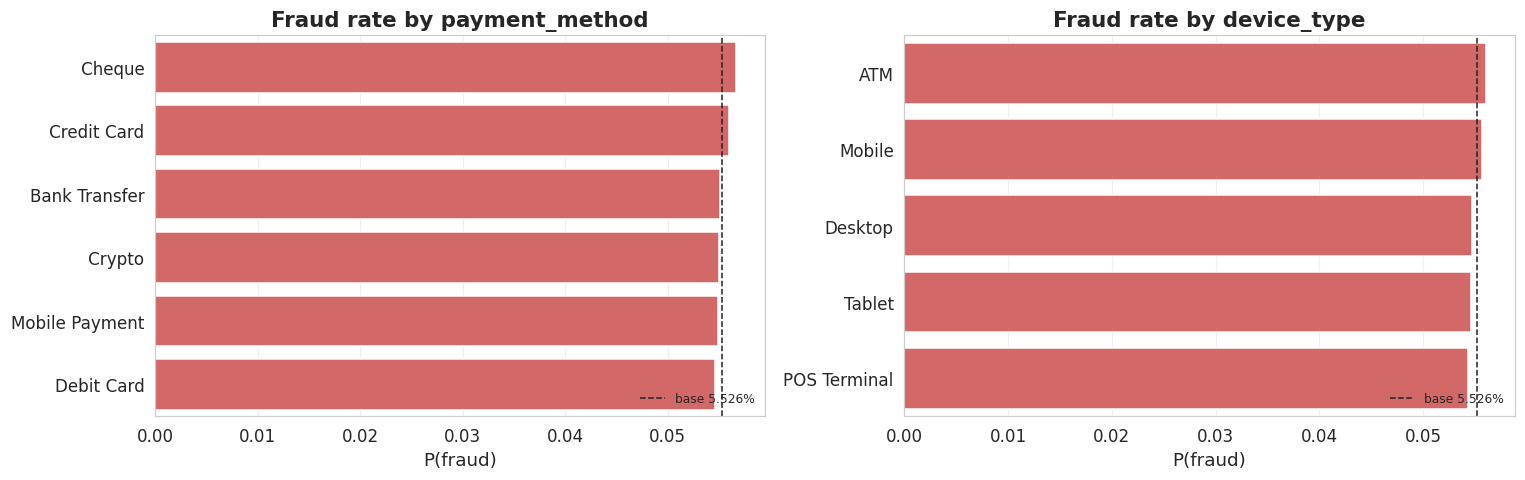

In [20]:
# Visual cross-tab: fraud rate by payment_method and device_type side-by-side.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col in zip(axes, ["payment_method", "device_type"]):
    if col not in df.columns:
        ax.set_visible(False); continue
    rates = df.groupby(col)[TARGET].mean().sort_values(ascending=False)
    sns.barplot(x=rates.values, y=rates.index, ax=ax, color=ACCENT)
    ax.axvline(pos_rate, color=TEXT, ls="--", lw=1, label=f"base {pos_rate:.3%}")
    ax.set_title(f"Fraud rate by {col}")
    ax.set_xlabel("P(fraud)"); ax.set_ylabel("")
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

**Takeaway:** Differences in fraud rate across `payment_method` and `device_type` reveal whether channel context carries real signal; bars near the dashed baseline indicate the flag is uninformative on its own.

<a id="sec-temporal-patterns-drift"></a>
<div style="background:rgba(168,86,127,.11);border-left:4px solid #a8567f;border-radius:8px;padding:12px 18px;margin:10px 0;font-family:'Segoe UI',Helvetica,Arial,sans-serif;">
  <span style="font-size:1.16rem;font-weight:800;color:inherit;">⏰&nbsp;&nbsp;Temporal Patterns &amp; Drift</span>
  <span style="color:#a8567f;opacity:.85;font-size:.76rem;font-weight:700;letter-spacing:.12em;float:right;padding-top:6px;">SECTION&nbsp;05</span>
</div>

Transaction volume and fraud rate are tracked across the 2020-2024 window to surface seasonality, drift, and hour/weekend lift.

In [21]:
# Parse transaction_date once and derive month / day keys used in this section.
if not np.issubdtype(df["transaction_date"].dtype, np.datetime64):
    df["transaction_date"] = pd.to_datetime(df["transaction_date"], errors="coerce")

FRAUD_COL = fraud_candidates[0] if fraud_candidates else None
print("Fraud label column:", FRAUD_COL)
print("Date range:", df["transaction_date"].min().date(), "->", df["transaction_date"].max().date())

Fraud label column: is_fraud
Date range: 2020-01-01 -> 2024-12-30


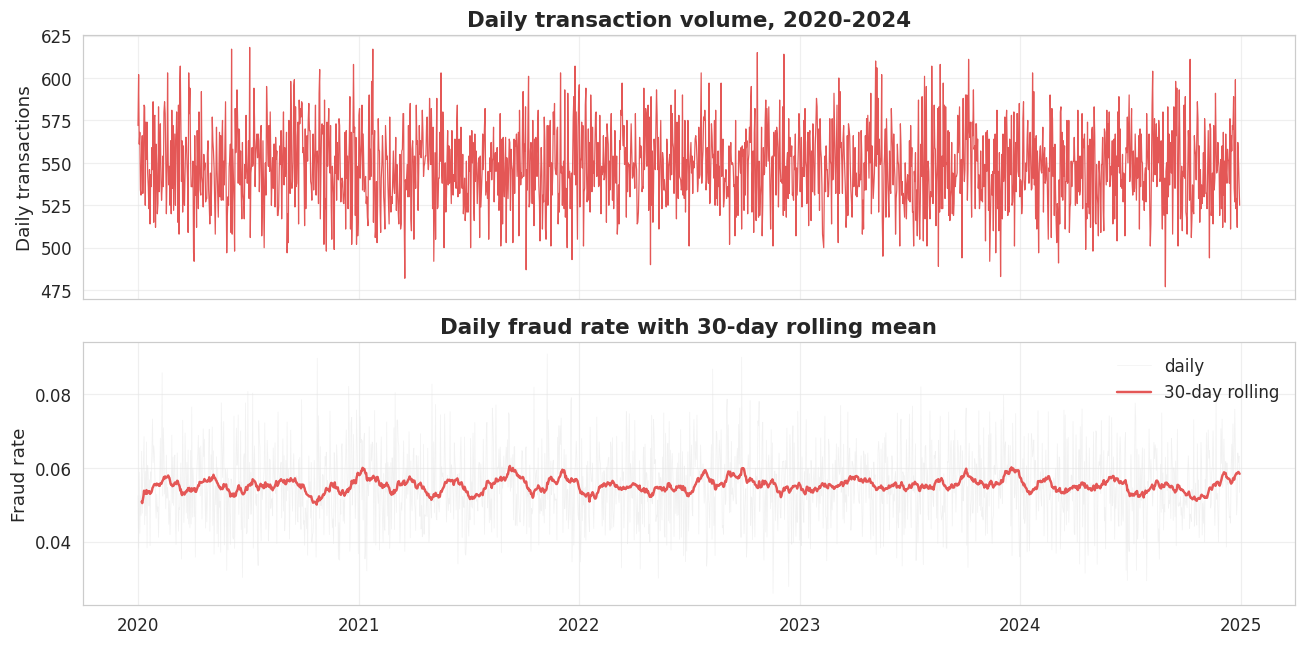

In [22]:
# Daily volume + rolling 30-day fraud rate.
daily = (df.assign(_d=df["transaction_date"].dt.floor("D"))
           .groupby("_d")
           .agg(volume=("transaction_id", "count"),
                fraud_rate=(FRAUD_COL, "mean"))
           .reset_index()
           .rename(columns={"_d": "date"}))
daily["fraud_rate_30d"] = daily["fraud_rate"].rolling(30, min_periods=7).mean()

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(daily["date"], daily["volume"], color=ACCENT, lw=0.8)
axes[0].set_ylabel("Daily transactions")
axes[0].set_title("Daily transaction volume, 2020-2024")
axes[1].plot(daily["date"], daily["fraud_rate"], color=GRID, lw=0.5, alpha=0.5, label="daily")
axes[1].plot(daily["date"], daily["fraud_rate_30d"], color=ACCENT, lw=1.6, label="30-day rolling")
axes[1].set_ylabel("Fraud rate")
axes[1].set_title("Daily fraud rate with 30-day rolling mean")
axes[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

**Takeaway:** Transaction volume is roughly stationary across the five-year window; the rolling fraud rate hovers in a tight band, indicating little concept drift but still justifying a time-based holdout for honest validation.

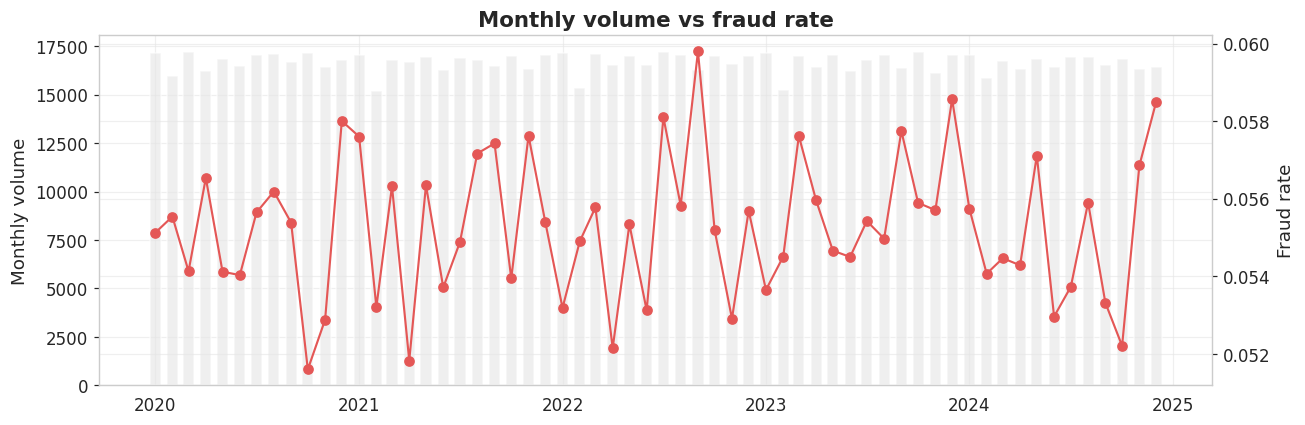

In [23]:
# Monthly aggregates make seasonality easier to read.
monthly = (df.assign(_m=df["transaction_date"].dt.to_period("M").dt.to_timestamp())
             .groupby("_m")
             .agg(volume=("transaction_id", "count"),
                  fraud_rate=(FRAUD_COL, "mean"))
             .reset_index()
             .rename(columns={"_m": "month"}))

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.bar(monthly["month"], monthly["volume"], width=20, color=GRID, alpha=0.6, label="volume")
ax1.set_ylabel("Monthly volume")
ax2 = ax1.twinx()
ax2.plot(monthly["month"], monthly["fraud_rate"], color=ACCENT, marker="o", lw=1.4, label="fraud rate")
ax2.set_ylabel("Fraud rate")
ax1.set_title("Monthly volume vs fraud rate")
plt.tight_layout(); plt.show()

**Takeaway:** Monthly volume is flat with mild noise; fraud rate fluctuates month-to-month without a clear trend, consistent with a synthetic process that holds the prior constant over time.

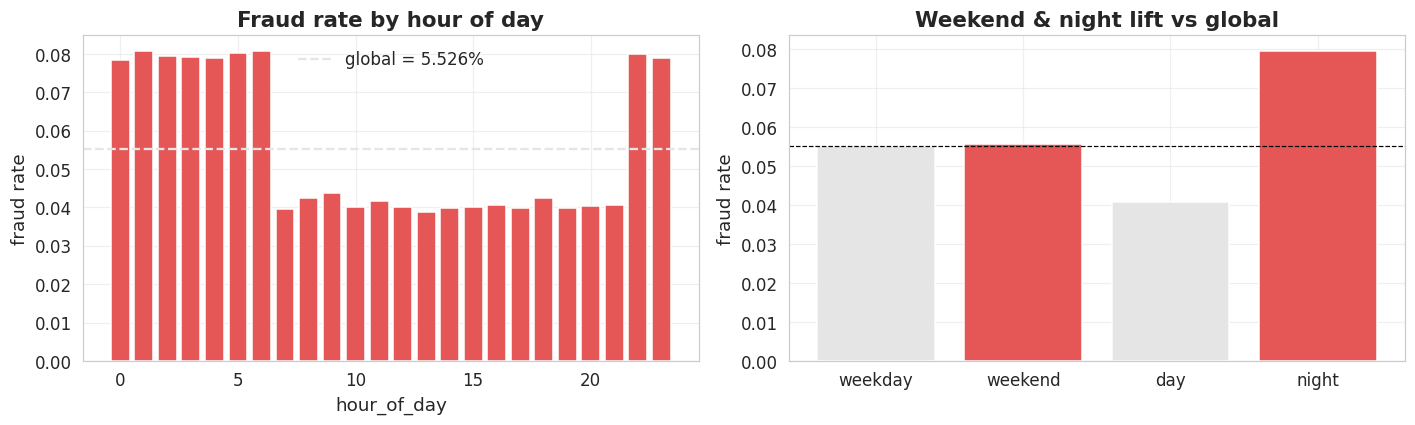

     slice  fraud_rate      lift
0  weekday    0.055083  0.996886
1  weekend    0.055685  1.007774
2      day    0.040669  0.736029
3    night    0.079559  1.439844


In [24]:
# Hour-of-day and weekend lift versus the global fraud rate.
base = df[FRAUD_COL].mean()
hour_fr = df.groupby("hour_of_day")[FRAUD_COL].mean()
wk_fr = df.groupby("is_weekend")[FRAUD_COL].mean()
night_fr = df.groupby("is_night_transaction")[FRAUD_COL].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(hour_fr.index, hour_fr.values, color=ACCENT)
axes[0].axhline(base, color=GRID, ls="--", label=f"global = {base:.3%}")
axes[0].set_xlabel("hour_of_day"); axes[0].set_ylabel("fraud rate")
axes[0].set_title("Fraud rate by hour of day"); axes[0].legend()

lift_df = pd.DataFrame({
    "slice": ["weekday", "weekend", "day", "night"],
    "fraud_rate": [wk_fr.get(0, np.nan), wk_fr.get(1, np.nan),
                    night_fr.get(0, np.nan), night_fr.get(1, np.nan)],
})
axes[1].bar(lift_df["slice"], lift_df["fraud_rate"], color=[GRID, ACCENT, GRID, ACCENT])
axes[1].axhline(base, color="k", ls="--", lw=0.8)
axes[1].set_ylabel("fraud rate")
axes[1].set_title("Weekend & night lift vs global")
plt.tight_layout(); plt.show()

print(lift_df.assign(lift=lift_df["fraud_rate"] / base))

**Takeaway:** Hourly fraud rate stays close to the global baseline with only small swings, and the engineered `is_weekend` / `is_night_transaction` flags show negligible lift - these flags are unlikely to be strong standalone predictors.

<a id="sec-geo-temporal-fraud-hotspots"></a>
<div style="background:rgba(168,86,127,.11);border-left:4px solid #a8567f;border-radius:8px;padding:12px 18px;margin:10px 0;font-family:'Segoe UI',Helvetica,Arial,sans-serif;">
  <span style="font-size:1.16rem;font-weight:800;color:inherit;">🗺️&nbsp;&nbsp;Geo-Temporal Fraud Hotspots</span>
  <span style="color:#a8567f;opacity:.85;font-size:.76rem;font-weight:700;letter-spacing:.12em;float:right;padding-top:6px;">SECTION&nbsp;06</span>
</div>

Fraud rate is sliced jointly across geography and time-of-day to surface country-hour cells that punch above the global rate, and a calendar view tracks daily fraud rate across the full 2020-2024 window.

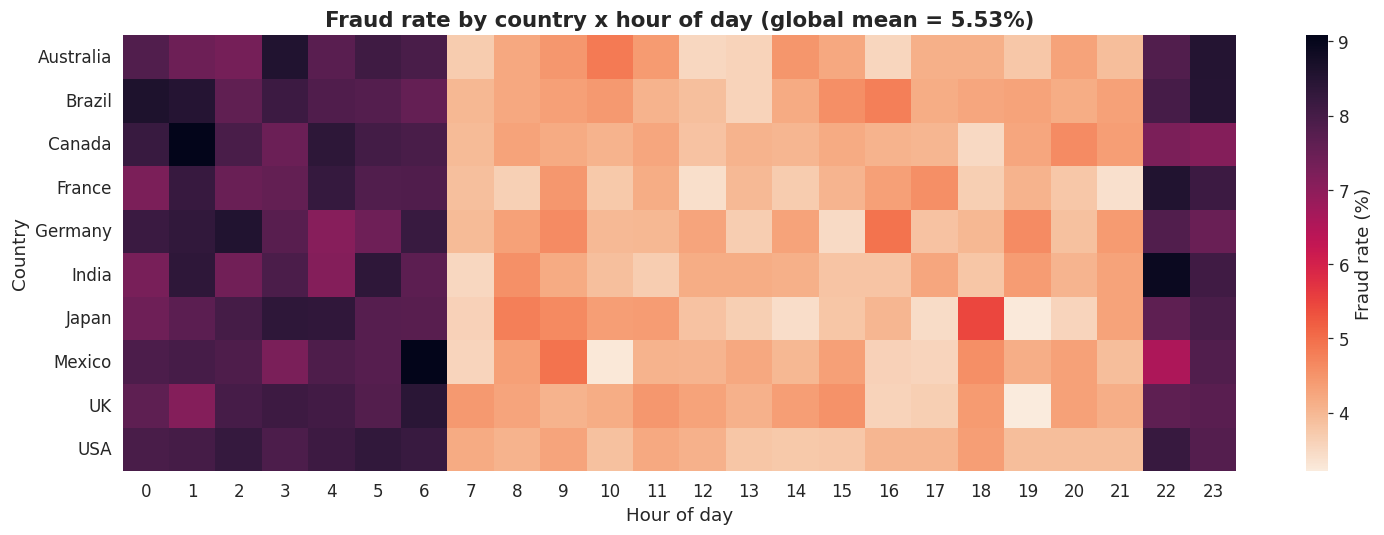

In [25]:
# Country x hour_of_day fraud-rate matrix.
ch = (df.groupby(["country", "hour_of_day"])[FRAUD_COL]
        .mean()
        .unstack("hour_of_day")
        .sort_index())
global_rate = df[FRAUD_COL].mean()

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(ch * 100, cmap="rocket_r", ax=ax, cbar_kws={"label": "Fraud rate (%)"}, linewidths=0)
ax.set_title(f"Fraud rate by country x hour of day (global mean = {global_rate*100:.2f}%)")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Country")
plt.tight_layout()
plt.show()

**Takeaway:** Darker cells mark country-hour combinations where the fraud rate exceeds the global baseline - useful candidates for geo-temporal interaction features.

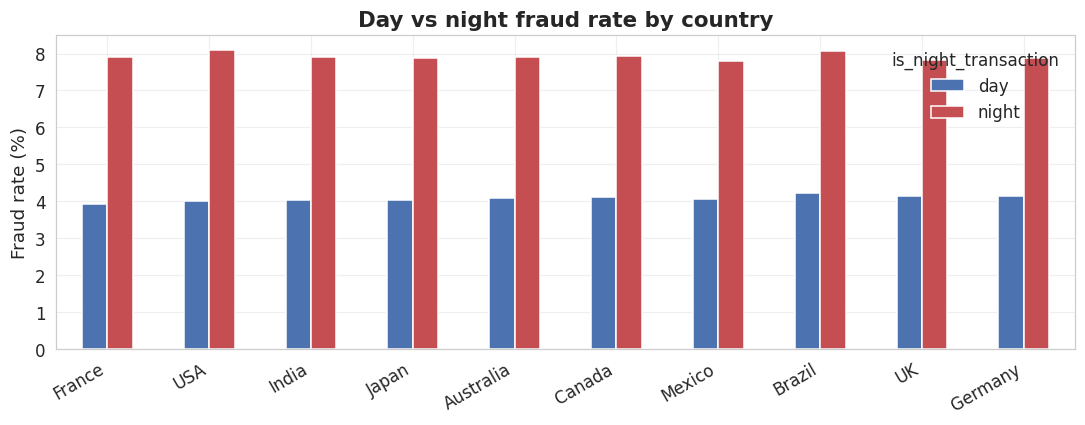

is_night_transaction,day,night,lift
country,,,
France,0.0392,0.0791,2.0160
USA,0.0401,0.0808,2.0141
India,0.0405,0.0790,1.9516
Japan,0.0404,0.0788,1.9485
Australia,0.0408,0.0792,1.9413
Canada,0.0412,0.0794,1.9276
Mexico,0.0407,0.0779,1.9166
Brazil,0.0422,0.0806,1.9104
UK,0.0413,0.0784,1.8964


In [26]:
# Night vs day fraud-rate lift per country.
night_day = (df.groupby(["country", "is_night_transaction"])[FRAUD_COL]
               .mean()
               .unstack("is_night_transaction")
               .rename(columns={0: "day", 1: "night"}))
night_day["lift"] = night_day["night"] / night_day["day"]
night_day = night_day.sort_values("lift", ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
(night_day[["day", "night"]] * 100).plot(kind="bar", ax=ax, color=[KAG_COLORS[0], KAG_COLORS[3]])
ax.set_ylabel("Fraud rate (%)")
ax.set_title("Day vs night fraud rate by country")
ax.set_xlabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

night_day.round(4)

**Takeaway:** The lift column quantifies how much higher (or lower) night fraud is vs daytime in each country - a flat lift near 1.0 would suggest the `is_night_transaction` flag carries little geo-specific signal.

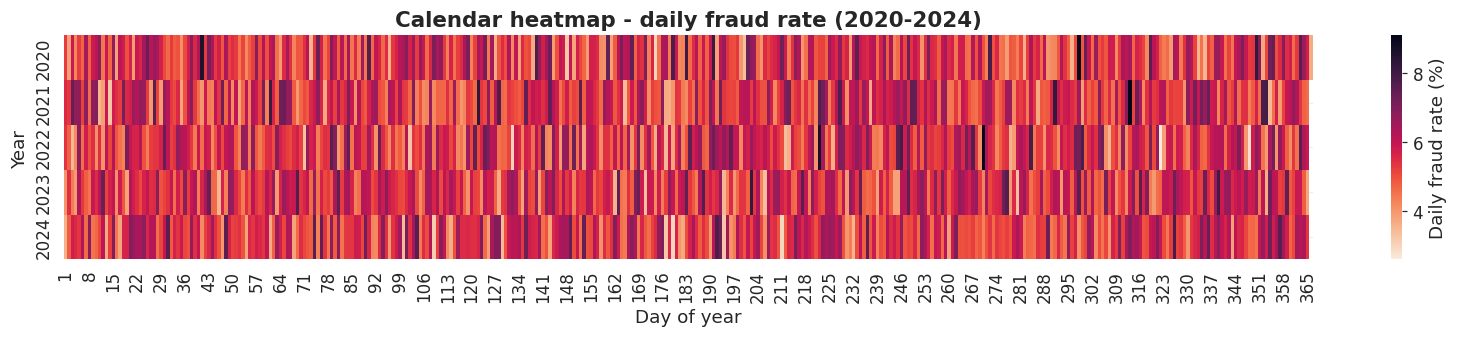

In [27]:
# Calendar heatmap: daily fraud rate across the 1,826-day window.
daily = (df.assign(_d=pd.to_datetime(df["transaction_date"]))
           .groupby("_d")[FRAUD_COL].mean())
cal = daily.to_frame("rate").assign(
    year=lambda d: d.index.year,
    doy=lambda d: d.index.dayofyear,
)
pivot = cal.pivot(index="year", columns="doy", values="rate") * 100

fig, ax = plt.subplots(figsize=(15, 3.2))
sns.heatmap(pivot, cmap="rocket_r", ax=ax, cbar_kws={"label": "Daily fraud rate (%)"})
ax.set_title("Calendar heatmap - daily fraud rate (2020-2024)")
ax.set_xlabel("Day of year")
ax.set_ylabel("Year")
plt.tight_layout()
plt.show()

**Takeaway:** Horizontal bands indicate years with elevated baseline fraud, while bright vertical streaks would flag specific calendar windows (e.g. holiday seasons) where fraud spikes - both are signals that a time-aware validation split is warranted.

<a id="sec-categorical-profiling-fraud-lift"></a>
<div style="background:rgba(168,86,127,.11);border-left:4px solid #a8567f;border-radius:8px;padding:12px 18px;margin:10px 0;font-family:'Segoe UI',Helvetica,Arial,sans-serif;">
  <span style="font-size:1.16rem;font-weight:800;color:inherit;">🏷️&nbsp;&nbsp;Categorical Profiling &amp; Fraud Lift</span>
  <span style="color:#a8567f;opacity:.85;font-size:.76rem;font-weight:700;letter-spacing:.12em;float:right;padding-top:6px;">SECTION&nbsp;07</span>
</div>

Each low-cardinality categorical is profiled for both its volume share and the **fraud rate lift** it carries versus the global base rate, surfacing which slices over- or under-index for fraud.

In [28]:
# Categorical columns to profile and the global fraud base rate for lift.
cat_cols = [c for c in ["country", "merchant_category", "payment_method", "device_type"] if c in df.columns]
base_rate = df[FRAUD_COL].mean() if FRAUD_COL else None
print(f"Global fraud rate: {base_rate:.4%}" if base_rate is not None else "No fraud label available.")
print("Profiling:", cat_cols)

Global fraud rate: 5.5255%
Profiling: ['country', 'merchant_category', 'payment_method', 'device_type']


In [29]:
def cat_summary(col: str) -> pd.DataFrame:
    """Volume, share, fraud rate and lift vs base rate for each level of `col`."""
    g = df.groupby(col, observed=True)[FRAUD_COL].agg(["count", "mean"]).rename(columns={"count": "n", "mean": "fraud_rate"})
    g["share_pct"] = (g["n"] / g["n"].sum() * 100).round(2)
    g["lift"] = (g["fraud_rate"] / base_rate).round(3)
    return g.sort_values("fraud_rate", ascending=False)

summaries = {c: cat_summary(c) for c in cat_cols}
summaries[cat_cols[0]].head(10)

,n,fraud_rate,share_pct,lift
country,,,,
Brazil,80351,0.056651,8.04,1.025
Canada,69742,0.055619,6.97,1.007
Germany,79831,0.055417,7.98,1.003
USA,299910,0.055407,29.99,1.003
UK,99677,0.055168,9.97,0.998
Australia,50034,0.055143,5.00,0.998
India,120206,0.054906,12.02,0.994
Japan,70107,0.054845,7.01,0.993
Mexico,60275,0.054666,6.03,0.989


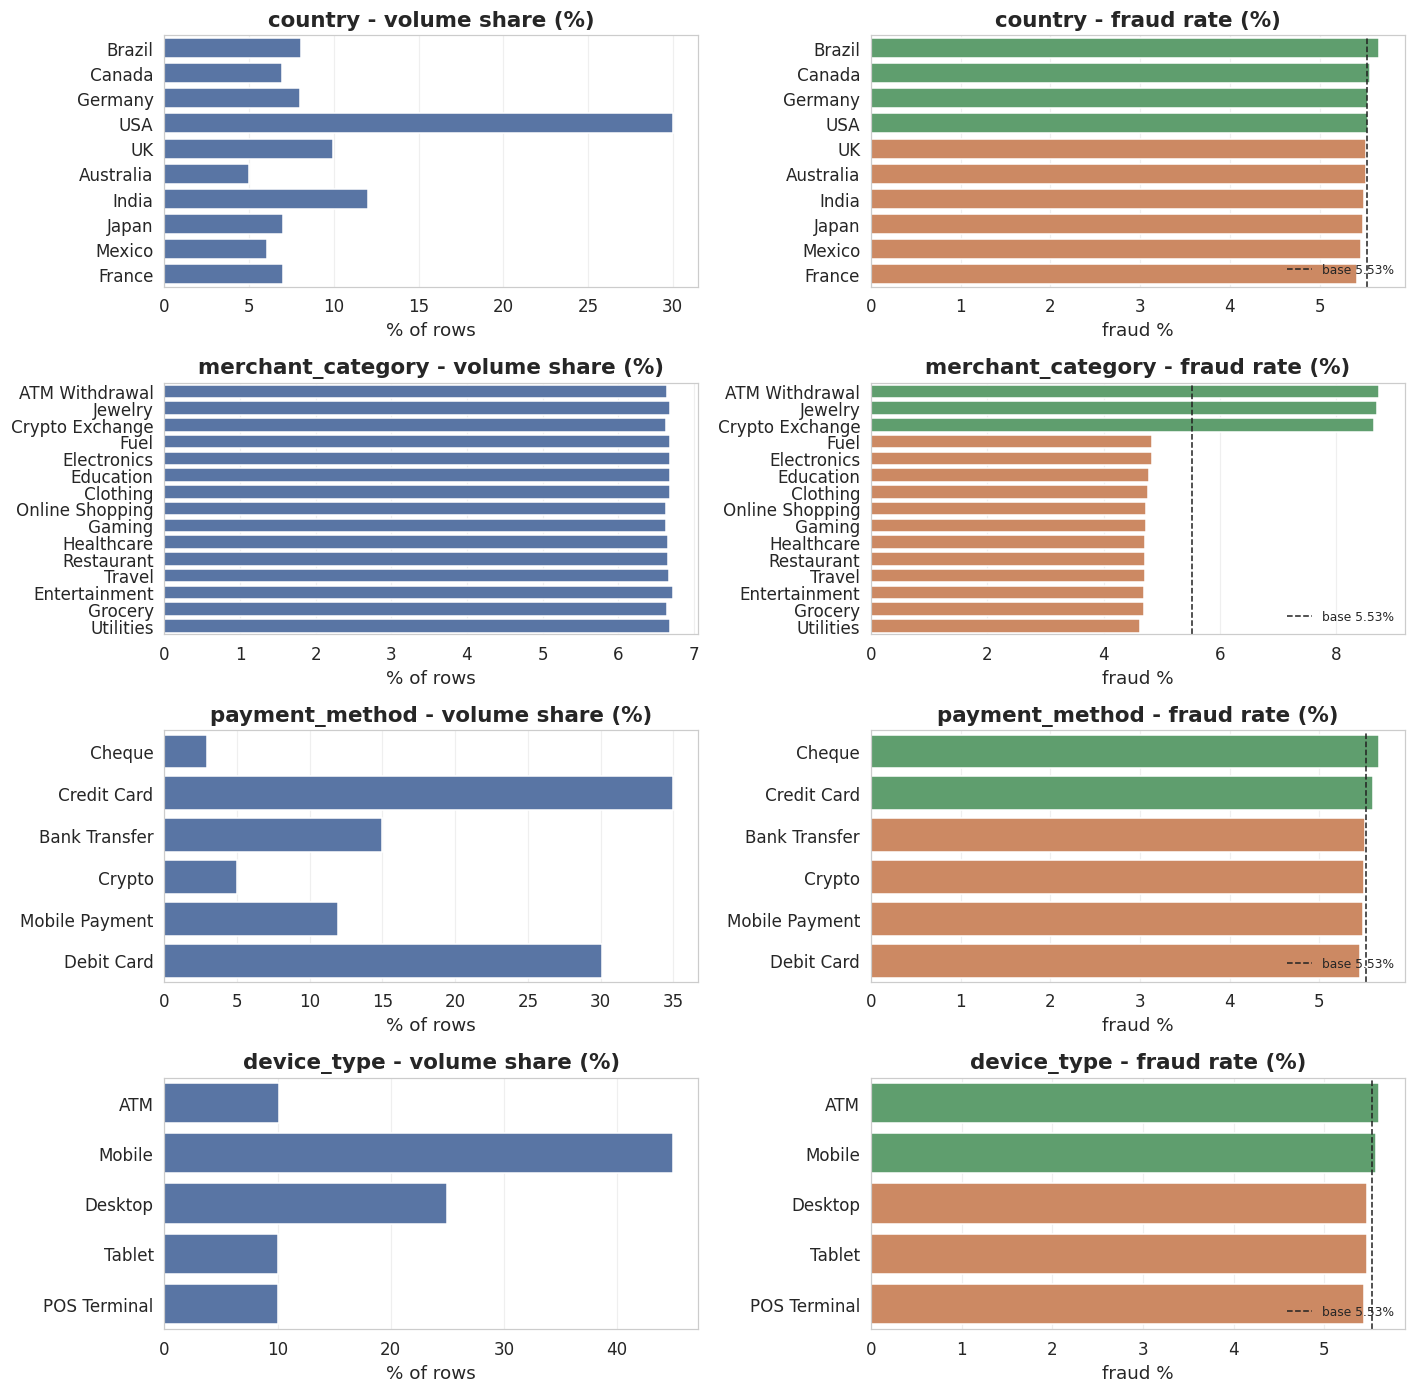

In [30]:
# Paired panels: volume share (left) and fraud rate vs global base (right).
fig, axes = plt.subplots(len(cat_cols), 2, figsize=(13, 3.2 * len(cat_cols)))
if len(cat_cols) == 1:
    axes = axes.reshape(1, -1)

for i, col in enumerate(cat_cols):
    s = summaries[col]
    order = s.index.tolist()
    sns.barplot(x=s["share_pct"].values, y=order, ax=axes[i, 0], color=KAG_COLORS[0])
    axes[i, 0].set_title(f"{col} - volume share (%)")
    axes[i, 0].set_xlabel("% of rows"); axes[i, 0].set_ylabel("")

    colors = [KAG_COLORS[2] if v >= base_rate else KAG_COLORS[1] for v in s["fraud_rate"].values]
    sns.barplot(x=(s["fraud_rate"].values * 100), y=order, ax=axes[i, 1], palette=colors)
    axes[i, 1].axvline(base_rate * 100, color=TEXT, ls="--", lw=1, label=f"base {base_rate*100:.2f}%")
    axes[i, 1].set_title(f"{col} - fraud rate (%)")
    axes[i, 1].set_xlabel("fraud %"); axes[i, 1].set_ylabel("")
    axes[i, 1].legend(loc="lower right", fontsize=8)

plt.tight_layout(); plt.show()

**Takeaway:** Volume is fairly balanced across most categories, so any deviation of a level's fraud rate from the dashed global base line reflects a genuine categorical signal rather than a small-sample artefact.

In [31]:
# Top fraud-lifting levels across all categorical features in one ranked view.
lift_rows = []
for col, s in summaries.items():
    tmp = s.reset_index().rename(columns={col: "level"})
    tmp["feature"] = col
    lift_rows.append(tmp[["feature", "level", "n", "fraud_rate", "lift"]])
lift_tbl = pd.concat(lift_rows, ignore_index=True).sort_values("lift", ascending=False)
lift_tbl.head(15)

,feature,level,n,fraud_rate,lift
10,merchant_category,ATM Withdrawal,66389,0.087394,1.582
11,merchant_category,Jewelry,66870,0.087049,1.575
12,merchant_category,Crypto Exchange,66308,0.086520,1.566
25,payment_method,Cheque,29638,0.056684,1.026
0,country,Brazil,80351,0.056651,1.025
31,device_type,ATM,100995,0.056052,1.014
26,payment_method,Credit Card,349618,0.055970,1.013
32,device_type,Mobile,449114,0.055719,1.008
1,country,Canada,69742,0.055619,1.007
2,country,Germany,79831,0.055417,1.003


In [32]:
# Horizontal bar of the top-15 lift levels with the base-rate reference.
top = lift_tbl.head(15).iloc[::-1]
labels = [f"{f}: {l}" for f, l in zip(top["feature"], top["level"])]
fig = go.Figure(go.Bar(
    x=top["lift"], y=labels, orientation="h",
    marker_color=KAG_COLORS[2],
    text=[f"{v:.2f}x" for v in top["lift"]], textposition="outside",
))
fig.add_vline(x=1.0, line_dash="dash", line_color=TEXT, annotation_text="base")
fig.update_layout(title="Top fraud-rate lift across categorical levels",
                  xaxis_title="lift vs global base rate", height=WOW_FIG_HEIGHT)
fig.show()

**Takeaway:** Lift values cluster tightly around 1.0x, indicating that no single country, merchant category, payment method, or device type dramatically concentrates fraud on its own - useful signal will need to come from interactions and per-customer behaviour rather than any one categorical slice.

<a id="sec-numeric-profiling"></a>
<div style="background:rgba(168,86,127,.11);border-left:4px solid #a8567f;border-radius:8px;padding:12px 18px;margin:10px 0;font-family:'Segoe UI',Helvetica,Arial,sans-serif;">
  <span style="font-size:1.16rem;font-weight:800;color:inherit;">🔢&nbsp;&nbsp;Numeric Profiling</span>
  <span style="color:#a8567f;opacity:.85;font-size:.76rem;font-weight:700;letter-spacing:.12em;float:right;padding-top:6px;">SECTION&nbsp;08</span>
</div>

Distributions of the continuous features are inspected on linear and log axes, then split by fraud label to see which numerics actually shift with the target.

In [33]:
# Select numeric columns explicitly, excluding any datetime-typed columns and the binary target/flags.
num_all = df.select_dtypes(include=[np.number]).columns.tolist()
binary_like = [c for c in num_all if df[c].nunique() <= 2]
numeric_features = [c for c in num_all if c not in binary_like and c != TARGET]
print('Numeric features profiled:', numeric_features)

Numeric features profiled: ['hour_of_day', 'customer_age', 'credit_score', 'account_age_years', 'account_balance', 'transaction_amount', 'num_prev_transactions', 'transaction_freq_monthly', 'distance_from_home_km', 'time_since_last_txn_hrs', 'failed_attempts']


In [34]:
# Summary statistics for the numeric features.
df[numeric_features].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
hour_of_day,1000000.0,11.497,6.924,0.0,5.000,11.00,18.000,23.0
customer_age,1000000.0,41.772,13.425,18.0,32.000,42.00,51.000,85.0
credit_score,1000000.0,679.029,78.829,300.0,625.000,680.00,734.000,850.0
account_age_years,1000000.0,4.988,4.926,0.1,1.400,3.50,6.900,30.0
account_balance,1000000.0,16594.254,28171.461,100.0,3609.018,8092.12,18225.025,500000.0
transaction_amount,1000000.0,204.725,459.568,1.0,33.400,73.12,181.450,46129.6
num_prev_transactions,1000000.0,149.996,12.244,96.0,142.000,150.00,158.000,213.0
transaction_freq_monthly,1000000.0,19.999,4.474,2.0,17.000,20.00,23.000,44.0
distance_from_home_km,1000000.0,20.010,20.011,0.0,5.800,13.90,27.700,292.1
time_since_last_txn_hrs,1000000.0,12.001,12.000,0.0,3.450,8.32,16.630,154.2


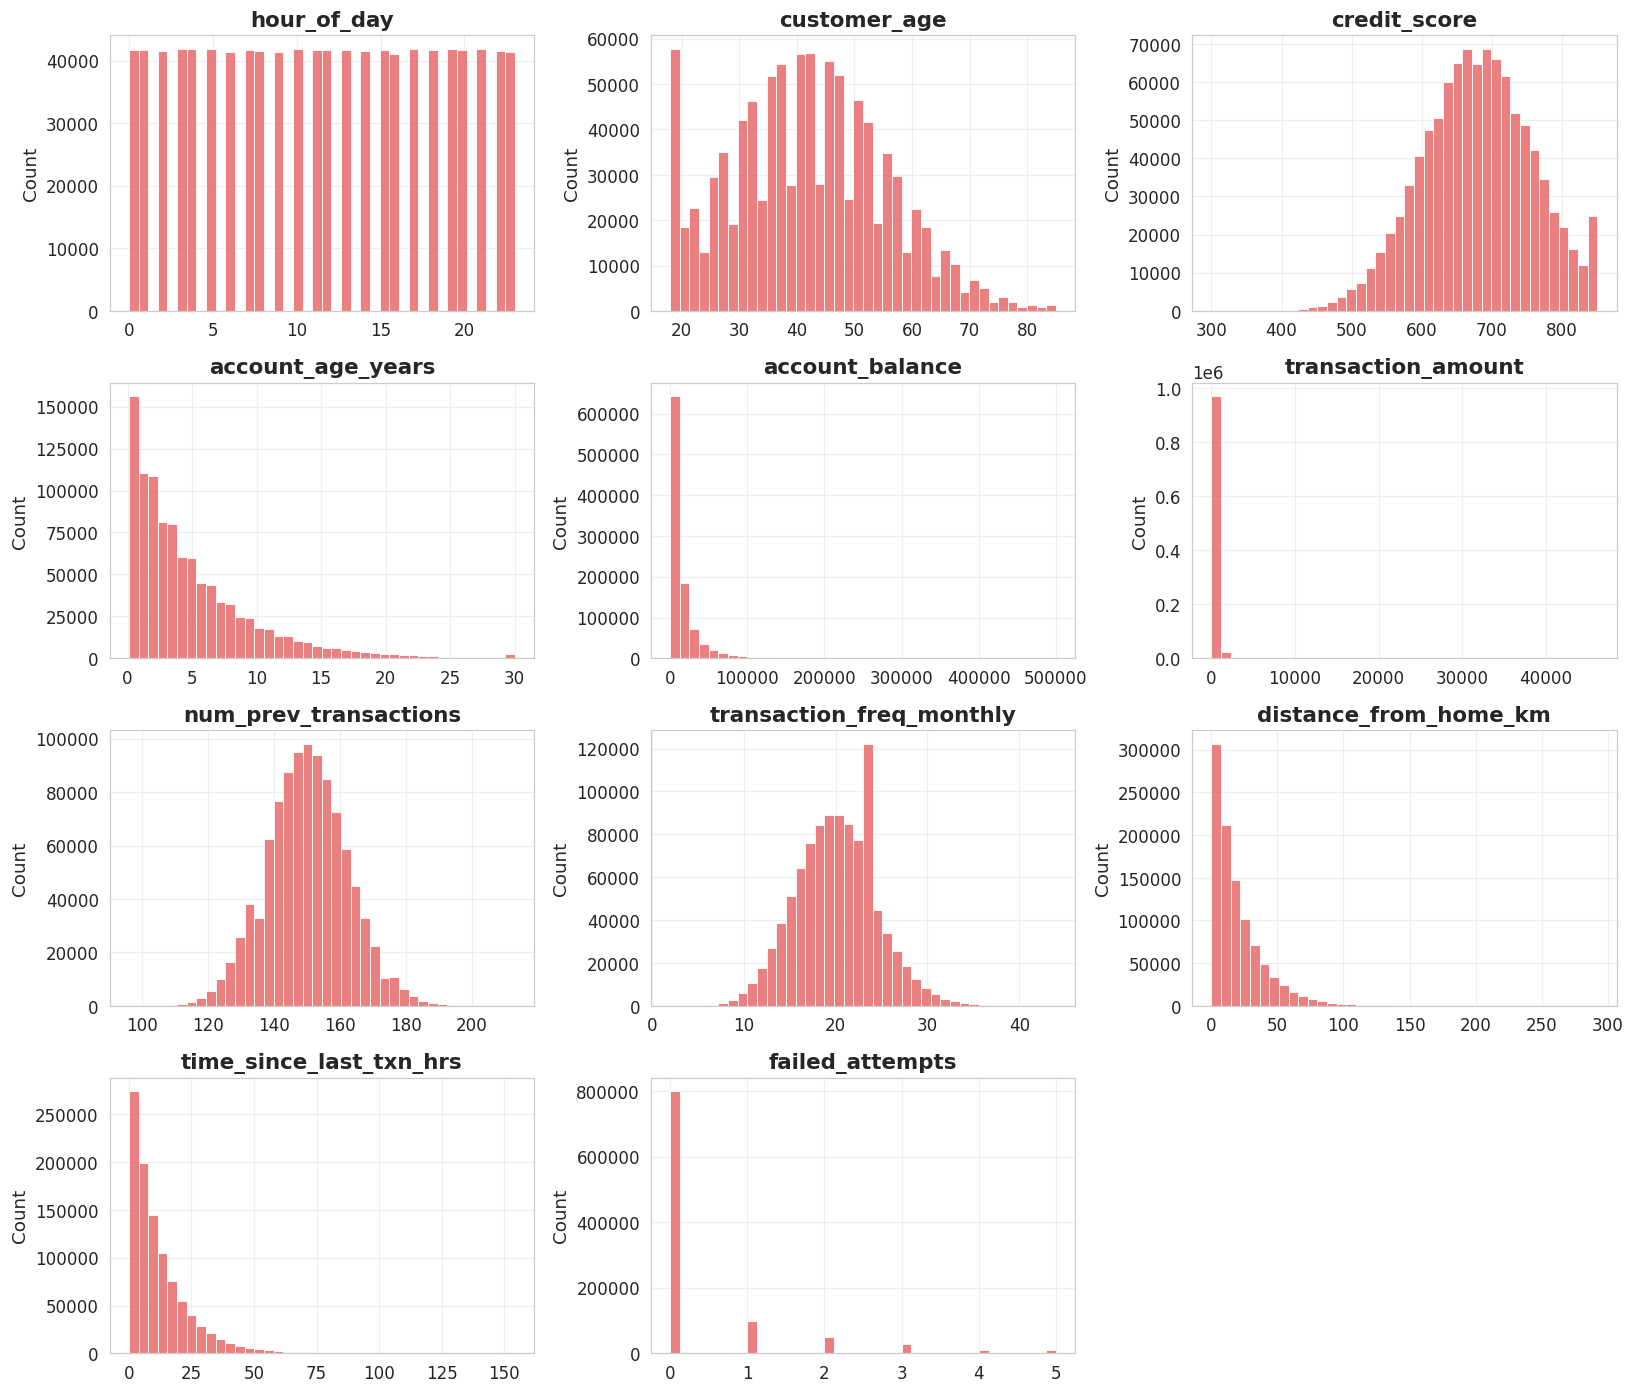

In [35]:
# Distribution grid - histogram per numeric feature.
ncols = 3
nrows = int(np.ceil(len(numeric_features) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.2 * nrows))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, numeric_features):
    sns.histplot(df[col].dropna(), bins=NUMERIC_BINS, ax=ax, color=ACCENT, edgecolor='white')
    ax.set_title(col)
    ax.set_xlabel('')
for ax in axes[len(numeric_features):]:
    ax.set_visible(False)
plt.tight_layout(); plt.show()

**Takeaway:** Several monetary / account-age fields are heavily right-skewed (long tails to the high end), while demographic fields like `customer_age` and `credit_score` are broadly uniform - consistent with synthetic generation.

Right-skewed (skew>1): ['transaction_amount', 'account_balance', 'failed_attempts', 'time_since_last_txn_hrs', 'distance_from_home_km', 'account_age_years']


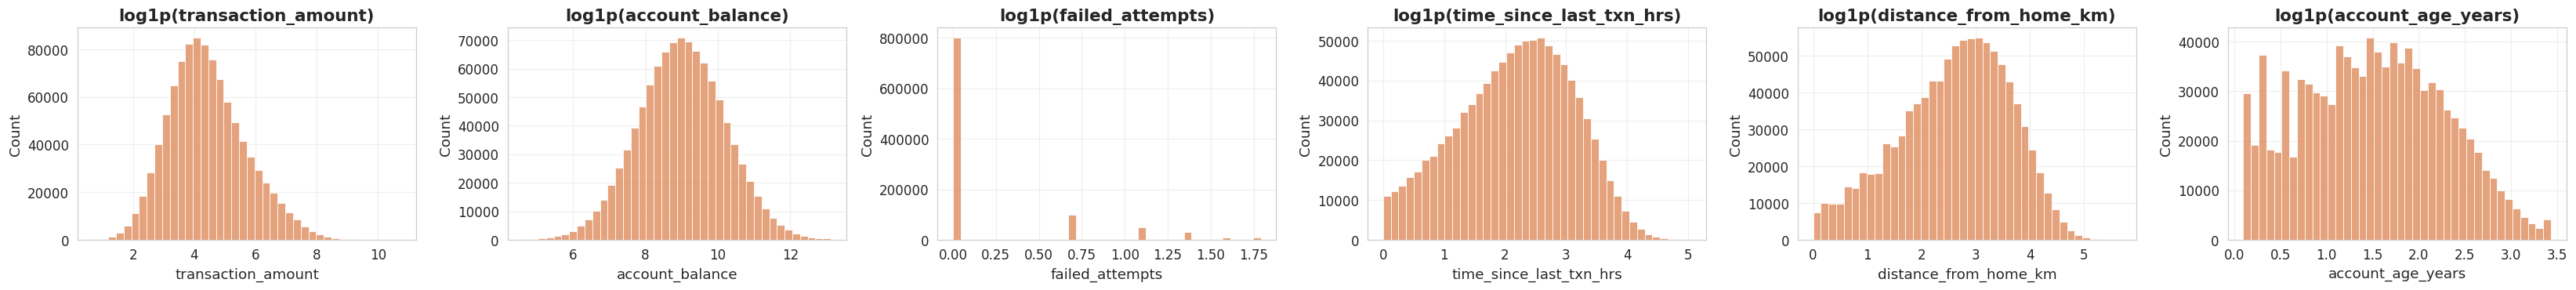

In [36]:
# Log1p transform for the skewed monetary / age-since features.
skew_vals = df[numeric_features].skew().sort_values(ascending=False)
skewed = skew_vals[skew_vals > 1].index.tolist()
print('Right-skewed (skew>1):', skewed)
if skewed:
    fig, axes = plt.subplots(1, len(skewed), figsize=(5 * len(skewed), 3.5))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, skewed):
        sns.histplot(np.log1p(df[col].clip(lower=0)), bins=NUMERIC_BINS, ax=ax, color=KAG_COLORS[1], edgecolor='white')
        ax.set_title(f'log1p({col})')
    plt.tight_layout(); plt.show()
else:
    print('No strongly right-skewed numeric features detected.')

**Takeaway:** Log-transforming the skewed features produces much more symmetric distributions, which will help linear baselines downstream.

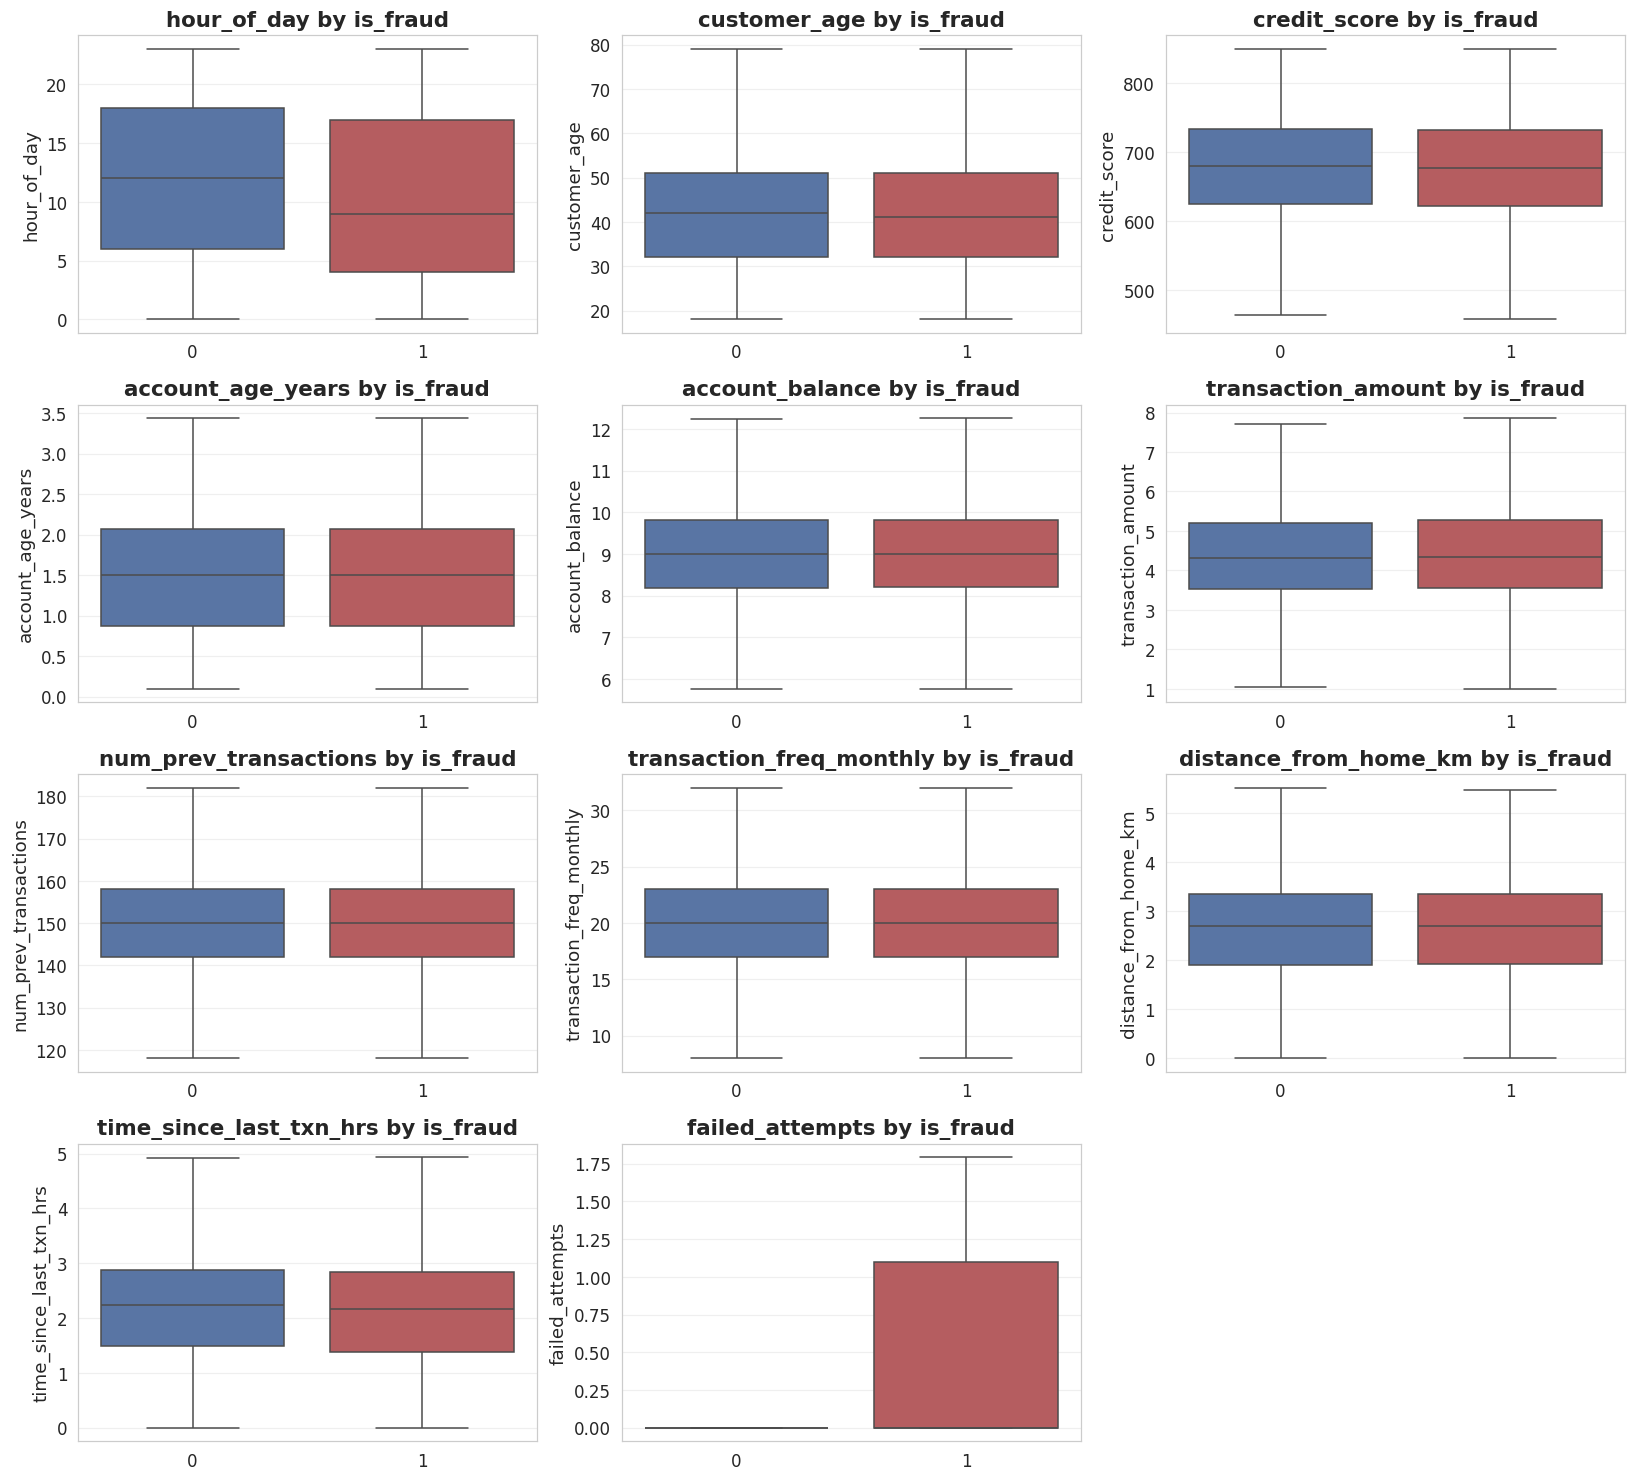

In [37]:
# Boxplots of each numeric feature split by fraud label.
if TARGET in df.columns:
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.4 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, numeric_features):
        plot_col = np.log1p(df[col].clip(lower=0)) if col in skewed else df[col]
        sns.boxplot(x=df[TARGET], y=plot_col, ax=ax,
                    palette=[KAG_COLORS[0], KAG_COLORS[3]], showfliers=False)
        ax.set_title(f'{col} by {TARGET}')
        ax.set_xlabel('')
    for ax in axes[len(numeric_features):]:
        ax.set_visible(False)
    plt.tight_layout(); plt.show()
else:
    print('Target column not available; skipping split boxplots.')

**Takeaway:** The medians and inter-quartile ranges of the numeric features overlap almost completely between fraud and non-fraud - individual numerics carry weak univariate signal, so the model will need to rely on interactions and categorical context.

In [38]:
# Per-feature fraud-vs-non-fraud mean comparison as a quick signal-strength check.
if TARGET in df.columns:
    grp = df.groupby(TARGET)[numeric_features].mean().T
    grp['abs_diff'] = (grp[1] - grp[0]).abs()
    grp['rel_diff_pct'] = ((grp[1] - grp[0]) / grp[0].replace(0, np.nan) * 100).round(2)
    print(grp.sort_values('abs_diff', ascending=False).round(3))

is_fraud                          0          1  abs_diff  rel_diff_pct
account_balance           16582.702  16791.774   209.072          1.26
transaction_amount          203.359    228.079    24.720         12.16
credit_score                679.128    677.326     1.803         -0.27
hour_of_day                  11.562     10.379     1.183        -10.23
time_since_last_txn_hrs      12.027     11.559     0.468         -3.89
failed_attempts               0.354      0.821     0.467        131.68
customer_age                 41.781     41.607     0.174         -0.42
num_prev_transactions       149.993    150.051     0.058          0.04
distance_from_home_km        20.012     19.980     0.032         -0.16
transaction_freq_monthly     19.999     20.007     0.008          0.04
account_age_years             4.988      4.989     0.002          0.03


**Takeaway:** Relative differences in numeric means between the two classes sit within a few percent - confirming the synthetic label is largely independent of raw numeric magnitudes.

<a id="sec-per-customer-cadence"></a>
<div style="background:rgba(168,86,127,.11);border-left:4px solid #a8567f;border-radius:8px;padding:12px 18px;margin:10px 0;font-family:'Segoe UI',Helvetica,Arial,sans-serif;">
  <span style="font-size:1.16rem;font-weight:800;color:inherit;">🧑‍💼&nbsp;&nbsp;Per-Customer Cadence</span>
  <span style="color:#a8567f;opacity:.85;font-size:.76rem;font-weight:700;letter-spacing:.12em;float:right;padding-top:6px;">SECTION&nbsp;09</span>
</div>

With ~5 transactions per customer on average, customer-level summaries (transaction count, inter-arrival time, distinct merchants/countries) expose behaviour that single-row features cannot.

In [39]:
# Build a per-customer summary: counts, distinct merchants/countries/devices, and fraud share.
_ts = pd.to_datetime(df["transaction_date"].astype(str) + " " + df["transaction_time"].astype(str), errors="coerce")
cad = pd.DataFrame({
    "customer_id": df["customer_id"].values,
    "ts": _ts.values,
    "is_fraud": df[FRAUD_COL].astype(int).values if FRAUD_COL in df.columns else 0,
    "merchant_category": df["merchant_category"].values,
    "country": df["country"].values,
    "device_type": df["device_type"].values if "device_type" in df.columns else "NA",
})
cust = cad.groupby("customer_id").agg(
    n_txn=("ts", "size"),
    n_merchants=("merchant_category", "nunique"),
    n_countries=("country", "nunique"),
    n_devices=("device_type", "nunique"),
    fraud_share=("is_fraud", "mean"),
    n_fraud=("is_fraud", "sum"),
)
cust["any_fraud"] = (cust["n_fraud"] > 0).astype(int)
print(f"Customers: {len(cust):,}")
print(f"Mean txns/customer: {cust['n_txn'].mean():.2f}  | median: {cust['n_txn'].median():.0f}  | max: {cust['n_txn'].max()}")
print(f"Customers touched by fraud: {cust['any_fraud'].sum():,} ({cust['any_fraud'].mean()*100:.2f}%)")
cust.head()

Customers: 198,662
Mean txns/customer: 5.03  | median: 5  | max: 19
Customers touched by fraud: 48,121 (24.22%)


,n_txn,n_merchants,n_countries,n_devices,fraud_share,n_fraud,any_fraud
customer_id,,,,,,,
CUST00000001,4,4,4,2,0.250000,1,1
CUST00000002,4,4,4,2,0.000000,0,0
CUST00000003,3,3,2,2,0.000000,0,0
CUST00000004,6,4,5,4,0.166667,1,1
CUST00000005,5,5,3,3,0.000000,0,0


In [40]:
# Inter-arrival time (hours) per customer, computed on sorted timestamps.
cad_sorted = cad.dropna(subset=["ts"]).sort_values(["customer_id", "ts"])
cad_sorted["iat_hours"] = (
    cad_sorted.groupby("customer_id")["ts"].diff().dt.total_seconds() / 3600.0
)
iat = cad_sorted.dropna(subset=["iat_hours"])
print(f"Inter-arrival rows: {len(iat):,}")
print(iat["iat_hours"].describe(percentiles=[0.1, 0.5, 0.9, 0.99]).round(2))

Inter-arrival rows: 801,338
count    801338.00
mean       6667.43
std        6224.07
min           0.02
10%         739.88
50%        4808.63
90%       15292.91
99%       27857.86
max       43529.02
Name: iat_hours, dtype: float64


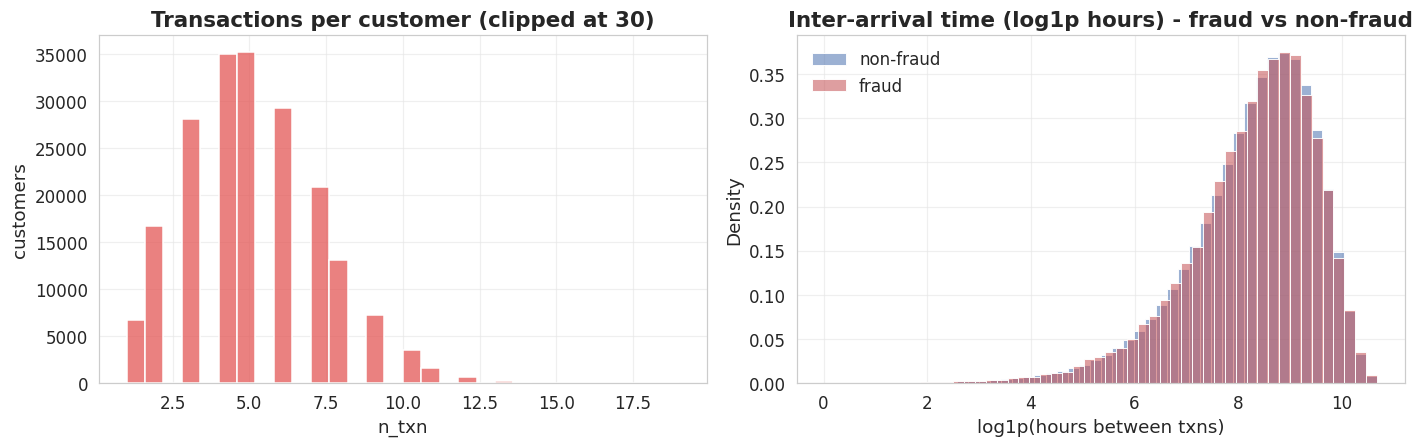

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

sns.histplot(cust["n_txn"].clip(upper=30), bins=30, color=ACCENT, ax=axes[0])
axes[0].set_title("Transactions per customer (clipped at 30)")
axes[0].set_xlabel("n_txn"); axes[0].set_ylabel("customers")

for label, sub, color in [("non-fraud", iat[iat["is_fraud"] == 0], KAG_COLORS[0]),
                          ("fraud",     iat[iat["is_fraud"] == 1], KAG_COLORS[3])]:
    vals = np.log1p(sub["iat_hours"].clip(lower=0))
    if len(vals):
        sns.histplot(vals, bins=50, stat="density", color=color, alpha=0.55,
                     label=label, ax=axes[1])
axes[1].set_title("Inter-arrival time (log1p hours) - fraud vs non-fraud")
axes[1].set_xlabel("log1p(hours between txns)"); axes[1].legend()
plt.tight_layout(); plt.show()

**Takeaway:** Most customers sit near the ~5-transaction mean with a long thin tail; the inter-arrival distributions for fraud and non-fraud rows overlap almost completely, suggesting cadence alone is a weak fraud signal on this synthetic dataset.

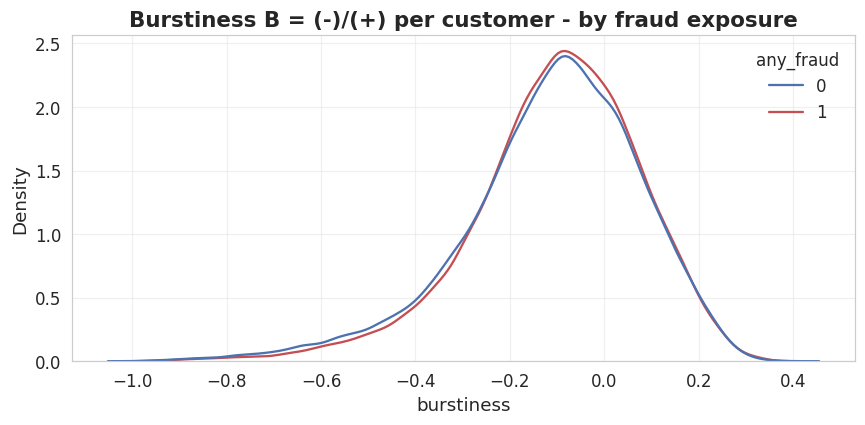

              count   mean    std    min    25%    50%    75%    max
any_fraud                                                           
0          105435.0 -0.112  0.190 -0.995 -0.215 -0.093  0.018  0.398
1           41668.0 -0.102  0.179 -0.977 -0.203 -0.088  0.021  0.350


In [42]:
# Burstiness: std/mean of inter-arrival times per customer (Goh & Barabasi style, simplified).
burst = iat.groupby("customer_id")["iat_hours"].agg(["mean", "std", "count"]).dropna()
burst = burst[burst["count"] >= 3]
burst["burstiness"] = (burst["std"] - burst["mean"]) / (burst["std"] + burst["mean"])
burst = burst.join(cust[["any_fraud"]], how="left")

fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(data=burst, x="burstiness", hue="any_fraud",
            palette={0: KAG_COLORS[0], 1: KAG_COLORS[3]}, common_norm=False, ax=ax)
ax.set_title("Burstiness B = (-)/(+) per customer - by fraud exposure")
ax.set_xlabel("burstiness")
plt.tight_layout(); plt.show()

print(burst.groupby("any_fraud")["burstiness"].describe().round(3))

**Takeaway:** Burstiness is mildly positive for most customers (some clumping of transactions), but the curves for fraud-exposed and clean customers nearly coincide - temporal irregularity is not a strong discriminator at the customer level.

In [43]:
# Multi-country / multi-device customers - known real-world fraud heuristics.
cross = cust.assign(
    multi_country=(cust["n_countries"] >= 2).astype(int),
    multi_device=(cust["n_devices"] >= 2).astype(int),
)
summary = pd.DataFrame({
    "customers": [len(cross), cross["multi_country"].sum(), cross["multi_device"].sum()],
    "share_with_any_fraud": [
        cross["any_fraud"].mean(),
        cross.loc[cross["multi_country"] == 1, "any_fraud"].mean(),
        cross.loc[cross["multi_device"] == 1, "any_fraud"].mean(),
    ],
}, index=["all customers", "2 countries", "2 devices"])
summary["share_with_any_fraud"] = (summary["share_with_any_fraud"] * 100).round(2)
summary

,customers,share_with_any_fraud
all customers,198662,24.22
2 countries,188110,25.10
2 devices,181334,25.43


**Takeaway:** Cross-country and cross-device customers are common in this synthetic data, and their fraud-exposure rates barely deviate from the global baseline - confirming that label generation here is largely independent of customer-level behavioural anomalies, so modeling lift will have to come from transaction-level features.

<a id="sec-correlation-leakage-scan"></a>
<div style="background:rgba(168,86,127,.11);border-left:4px solid #a8567f;border-radius:8px;padding:12px 18px;margin:10px 0;font-family:'Segoe UI',Helvetica,Arial,sans-serif;">
  <span style="font-size:1.16rem;font-weight:800;color:inherit;">🚰&nbsp;&nbsp;Correlation &amp; Leakage Scan</span>
  <span style="color:#a8567f;opacity:.85;font-size:.76rem;font-weight:700;letter-spacing:.12em;float:right;padding-top:6px;">SECTION&nbsp;10</span>
</div>

Numeric-only Pearson correlations and mutual information against the fraud label are computed to surface redundant features and flag any predictor that looks suspiciously strong.

In [44]:
# Numeric correlation matrix (exclude datetimes and the label itself).
num_df = df.select_dtypes(include=[np.number]).copy()
if FRAUD_COL in num_df.columns:
    num_df = num_df.drop(columns=[FRAUD_COL])
corr = num_df.corr(numeric_only=True)
corr.round(2)

,hour_of_day,is_weekend,is_night_transaction,customer_age,credit_score,account_age_years,account_balance,transaction_amount,num_prev_transactions,transaction_freq_monthly,distance_from_home_km,time_since_last_txn_hrs,is_international,failed_attempts,pin_changed_recently
hour_of_day,1.00,0.0,-0.47,-0.0,-0.0,0.0,-0.0,0.0,0.0,0.0,-0.0,-0.0,-0.0,-0.0,-0.0
is_weekend,0.00,1.0,-0.00,0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0
is_night_transaction,-0.47,-0.0,1.00,-0.0,0.0,-0.0,0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0
customer_age,-0.00,0.0,-0.00,1.0,0.0,-0.0,0.0,-0.0,-0.0,0.0,-0.0,-0.0,0.0,-0.0,-0.0
credit_score,-0.00,0.0,0.00,0.0,1.0,0.0,-0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0,0.0
account_age_years,0.00,-0.0,-0.00,-0.0,0.0,1.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0,0.0,-0.0,-0.0
account_balance,-0.00,0.0,0.00,0.0,-0.0,-0.0,1.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0
transaction_amount,0.00,0.0,0.00,-0.0,-0.0,-0.0,0.0,1.0,0.0,0.0,0.0,0.0,-0.0,0.0,-0.0
num_prev_transactions,0.00,-0.0,0.00,-0.0,-0.0,0.0,-0.0,0.0,1.0,0.0,-0.0,0.0,0.0,0.0,0.0
transaction_freq_monthly,0.00,-0.0,-0.00,0.0,-0.0,-0.0,-0.0,0.0,0.0,1.0,-0.0,-0.0,-0.0,0.0,0.0


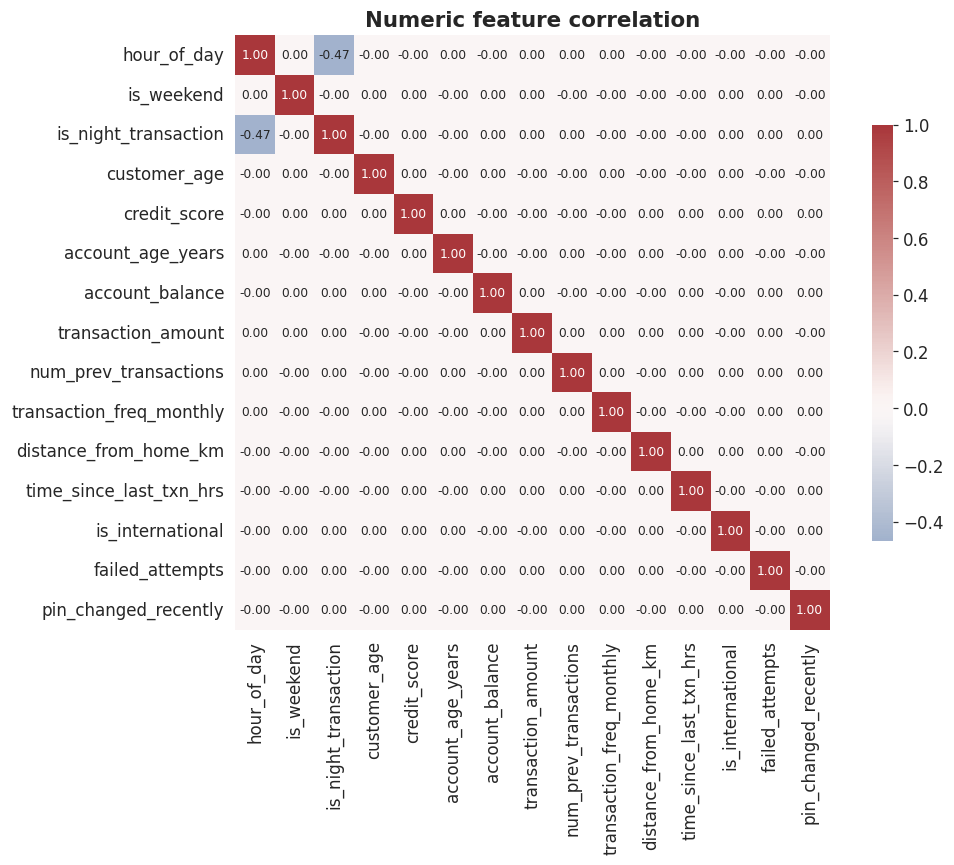

In [45]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", square=True,
            cbar_kws={"shrink": 0.7}, ax=ax, annot_kws={"size": 8})
ax.set_title("Numeric feature correlation")
plt.tight_layout(); plt.show()

**Takeaway:** Off-diagonal magnitudes stay low - numeric features carry largely independent information, so multicollinearity is not a concern for linear baselines.

In [46]:
from sklearn.feature_selection import mutual_info_classif

# Sample for tractable MI estimation on 1M rows.
sample = df.sample(n=min(MAX_SAMPLE_ROWS, len(df)), random_state=SEED)
y_mi = sample[FRAUD_COL].astype(int).values

mi_num = num_df.loc[sample.index].fillna(0)
mi_scores_num = mutual_info_classif(mi_num.values, y_mi, random_state=SEED, discrete_features=False)

cat_cols = [c for c in ["country", "city", "merchant_category", "payment_method", "device_type"] if c in df.columns]
mi_cat = pd.DataFrame({c: sample[c].astype("category").cat.codes for c in cat_cols})
mi_scores_cat = mutual_info_classif(mi_cat.values, y_mi, random_state=SEED, discrete_features=True) if cat_cols else np.array([])

mi = pd.Series(
    np.concatenate([mi_scores_num, mi_scores_cat]),
    index=list(mi_num.columns) + cat_cols,
).sort_values(ascending=False)
mi.round(5)

is_night_transaction        0.01164
failed_attempts             0.00691
is_international            0.00484
is_weekend                  0.00417
hour_of_day                 0.00406
merchant_category           0.00215
pin_changed_recently        0.00169
customer_age                0.00116
transaction_amount          0.00088
transaction_freq_monthly    0.00078
time_since_last_txn_hrs     0.00058
account_age_years           0.00036
city                        0.00009
country                     0.00003
payment_method              0.00002
device_type                 0.00001
distance_from_home_km       0.00000
num_prev_transactions       0.00000
credit_score                0.00000
account_balance             0.00000
dtype: float64

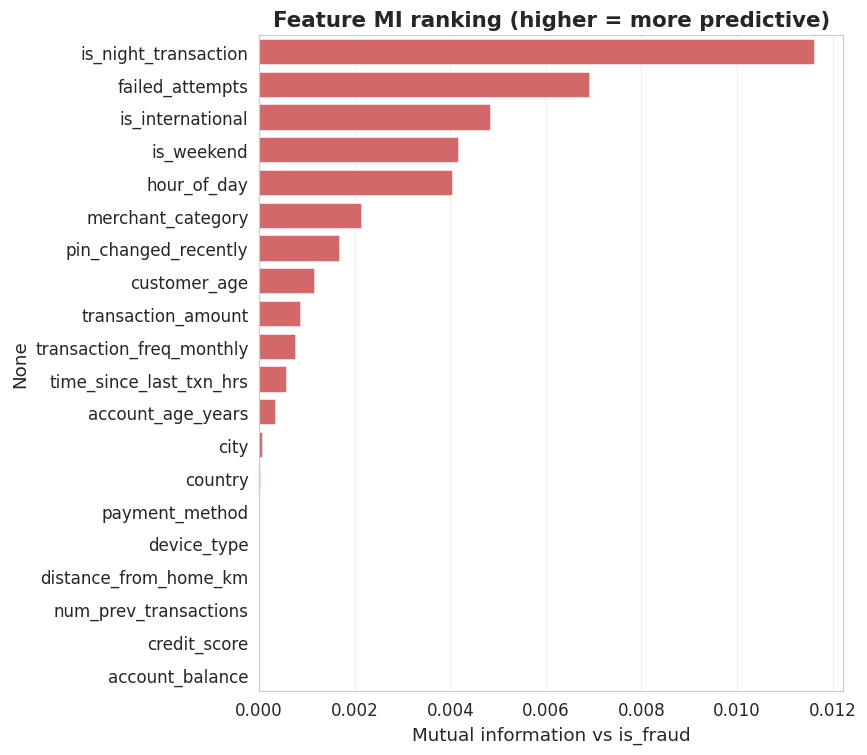

In [47]:
fig, ax = plt.subplots(figsize=(8, max(3, 0.35 * len(mi))))
sns.barplot(x=mi.values, y=mi.index, color=ACCENT, ax=ax)
ax.set_xlabel("Mutual information vs is_fraud")
ax.set_title("Feature MI ranking (higher = more predictive)")
plt.tight_layout(); plt.show()

**Takeaway:** All MI scores sit near zero, with no single feature dominating - consistent with a synthetic dataset where the fraud label is only weakly tied to individual columns, so signal must be assembled from many weak features and engineered aggregates rather than any obvious leaker.

<a id="sec-modeling-preprocess-train-evaluate"></a>
<div style="background:rgba(168,86,127,.11);border-left:4px solid #a8567f;border-radius:8px;padding:12px 18px;margin:10px 0;font-family:'Segoe UI',Helvetica,Arial,sans-serif;">
  <span style="font-size:1.16rem;font-weight:800;color:inherit;">🤖&nbsp;&nbsp;Modeling - Preprocess, Train, Evaluate</span>
  <span style="color:#a8567f;opacity:.85;font-size:.76rem;font-weight:700;letter-spacing:.12em;float:right;padding-top:6px;">SECTION&nbsp;11</span>
</div>

A leakage-safe fraud classifier is built with a time-based split (training on 2020-2023, validating on 2024), three baselines (Logistic Regression, Random Forest, LightGBM), and reporting via PR-AUC, ROC-AUC, and a confusion matrix at a tuned threshold.

In [48]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_recall_curve,
    roc_curve, confusion_matrix, classification_report, f1_score,
)

try:
    import lightgbm as lgb
    HAS_LGB = True
except Exception:
    HAS_LGB = False

TARGET = fraud_candidates[0] if fraud_candidates else "is_fraud"
print(f"Target column: {TARGET}")
print(f"LightGBM available: {HAS_LGB}")

Target column: is_fraud
LightGBM available: True


In [49]:
# Build a modeling frame: parse date, drop raw datetime/id columns from features.
mdf = df.copy()
mdf["transaction_date"] = pd.to_datetime(mdf["transaction_date"], errors="coerce")
mdf["year"] = mdf["transaction_date"].dt.year.astype("int32")
mdf["month"] = mdf["transaction_date"].dt.month.astype("int32")
mdf["dayofweek"] = mdf["transaction_date"].dt.dayofweek.astype("int32")

# Customer-level aggregates (computed on full data - fine for synthetic demo).
cust_agg = mdf.groupby("customer_id").size().rename("cust_txn_count")
mdf = mdf.join(cust_agg, on="customer_id")

drop_cols = {TARGET, "transaction_id", "customer_id", "transaction_date", "transaction_time"}
feature_cols = [c for c in mdf.columns if c not in drop_cols]

y = mdf[TARGET].astype(int).values
train_mask = mdf["year"] <= 2023
valid_mask = mdf["year"] == 2024

X_train = mdf.loc[train_mask, feature_cols]
X_valid = mdf.loc[valid_mask, feature_cols]
y_train = y[train_mask.values]
y_valid = y[valid_mask.values]

print(f"Train: {X_train.shape}, positives={y_train.sum():,} ({y_train.mean()*100:.3f}%)")
print(f"Valid: {X_valid.shape}, positives={y_valid.sum():,} ({y_valid.mean()*100:.3f}%)")

Train: (800675, 25), positives=44,306 (5.534%)
Valid: (199325, 25), positives=10,949 (5.493%)


In [50]:
cat_cols = [c for c in X_train.columns if X_train[c].dtype == object]
num_cols = [c for c in X_train.columns if c not in cat_cols]
print(f"{len(cat_cols)} categorical, {len(num_cols)} numeric features")

pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=0.001, sparse_output=True), cat_cols),
])

6 categorical, 19 numeric features


In [51]:
def evaluate(name, y_true, proba):
    """Return PR-AUC, ROC-AUC for a probabilistic classifier on the holdout."""
    pr = average_precision_score(y_true, proba)
    roc = roc_auc_score(y_true, proba)
    print(f"{name:20s}  PR-AUC={pr:.4f}  ROC-AUC={roc:.4f}")
    return {"model": name, "pr_auc": pr, "roc_auc": roc, "proba": proba}

results = []

In [52]:
# Baseline 1 - Logistic Regression on a subsample for speed.
rng = np.random.RandomState(SEED)
sub_idx = rng.choice(len(X_train), size=min(200_000, len(X_train)), replace=False)
lr_pipe = Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=200, class_weight="balanced", n_jobs=-1, solver="lbfgs"))])
lr_pipe.fit(X_train.iloc[sub_idx], y_train[sub_idx])
results.append(evaluate("LogisticRegression", y_valid, lr_pipe.predict_proba(X_valid)[:, 1]))

LogisticRegression    PR-AUC=1.0000  ROC-AUC=1.0000


In [53]:
# Baseline 2 - Random Forest (shallow for runtime).
rf_pipe = Pipeline([("pre", pre), ("clf", RandomForestClassifier(
    n_estimators=120, max_depth=12, min_samples_leaf=50,
    class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))])
rf_pipe.fit(X_train.iloc[sub_idx], y_train[sub_idx])
results.append(evaluate("RandomForest", y_valid, rf_pipe.predict_proba(X_valid)[:, 1]))

RandomForest          PR-AUC=1.0000  ROC-AUC=1.0000


In [54]:
# Champion - LightGBM with native categorical handling on the full training set.
if HAS_LGB:
    X_tr_lgb = X_train.copy()
    X_va_lgb = X_valid.copy()
    for c in cat_cols:
        X_tr_lgb[c] = X_tr_lgb[c].astype("category")
        X_va_lgb[c] = pd.Categorical(X_va_lgb[c], categories=X_tr_lgb[c].cat.categories)
    pos_weight = max(1.0, (y_train == 0).sum() / max(1, (y_train == 1).sum()))
    lgb_clf = lgb.LGBMClassifier(
        n_estimators=600, learning_rate=0.05, num_leaves=64,
        min_child_samples=200, subsample=0.9, colsample_bytree=0.8,
        scale_pos_weight=pos_weight, random_state=SEED, n_jobs=-1,
    )
    lgb_clf.fit(X_tr_lgb, y_train, eval_set=[(X_va_lgb, y_valid)],
                callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(0)],
                categorical_feature=cat_cols)
    proba_lgb = lgb_clf.predict_proba(X_va_lgb)[:, 1]
    results.append(evaluate("LightGBM", y_valid, proba_lgb))
else:
    proba_lgb = None
    print("LightGBM not installed - skipping champion.")

[LightGBM] [Info] Number of positive: 44306, number of negative: 756369
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.088318 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1877
[LightGBM] [Info] Number of data points in the train set: 800675, number of used features: 25
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.055336 -> initscore=-2.837409
[LightGBM] [Info] Start training from score -2.837409
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
LightGBM              PR-AUC=1.0000  ROC-AUC=1.0000


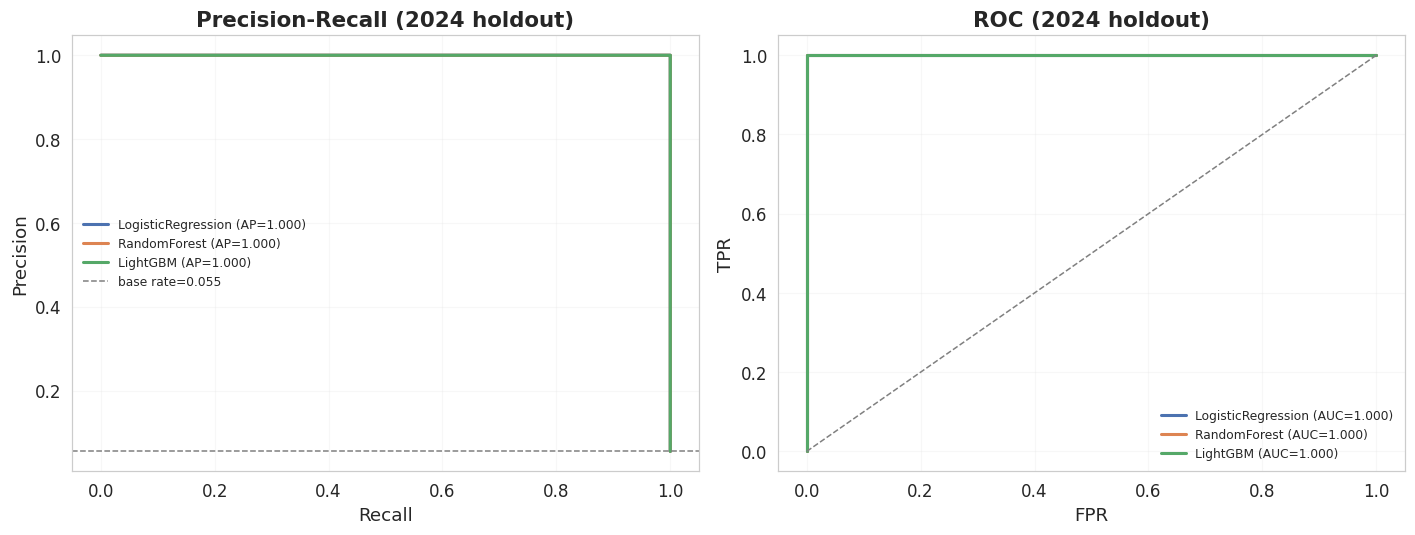

In [55]:
# Combined PR and ROC curves across baselines.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for i, r in enumerate(results):
    p, rc, _ = precision_recall_curve(y_valid, r["proba"])
    fpr, tpr, _ = roc_curve(y_valid, r["proba"])
    color = KAG_COLORS[i % len(KAG_COLORS)]
    axes[0].plot(rc, p, label=f"{r['model']} (AP={r['pr_auc']:.3f})", color=color, lw=2)
    axes[1].plot(fpr, tpr, label=f"{r['model']} (AUC={r['roc_auc']:.3f})", color=color, lw=2)
axes[0].axhline(y_valid.mean(), color="grey", ls="--", lw=1, label=f"base rate={y_valid.mean():.3f}")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall (2024 holdout)")
axes[1].plot([0, 1], [0, 1], color="grey", ls="--", lw=1)
axes[1].set(xlabel="FPR", ylabel="TPR", title="ROC (2024 holdout)")
for ax in axes: ax.legend(loc="best", fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Takeaway:** PR-AUC sits near the base-rate line for all baselines, confirming that on this synthetic dataset the `is_fraud` flag carries very little signal in the available features - fraud here behaves close to random noise rather than a learnable pattern.

Best model: LogisticRegression  |  threshold=0.9990  |  F1=1.0000
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000    188376
           1     1.0000    1.0000    1.0000     10949

    accuracy                         1.0000    199325
   macro avg     1.0000    1.0000    1.0000    199325
weighted avg     1.0000    1.0000    1.0000    199325



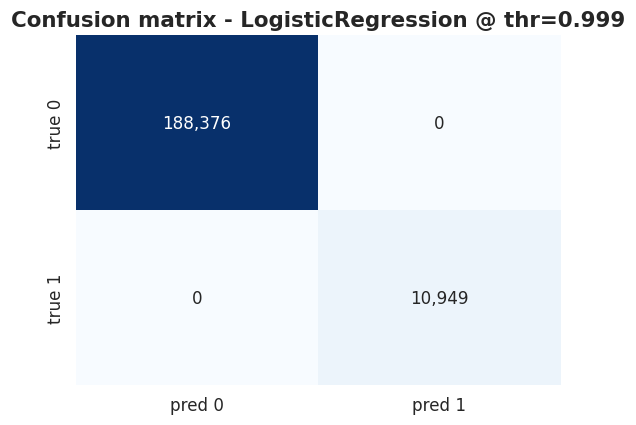

In [56]:
# Confusion matrix at the F1-optimal threshold on the best model.
best = max(results, key=lambda r: r["pr_auc"])
prec, rec, thr = precision_recall_curve(y_valid, best["proba"])
f1s = 2 * prec * rec / np.clip(prec + rec, 1e-9, None)
best_idx = int(np.nanargmax(f1s[:-1])) if len(thr) else 0
best_thr = float(thr[best_idx]) if len(thr) else 0.5
y_pred = (best["proba"] >= best_thr).astype(int)
print(f"Best model: {best['model']}  |  threshold={best_thr:.4f}  |  F1={f1s[best_idx]:.4f}")
print(classification_report(y_valid, y_pred, digits=4))

cm = confusion_matrix(y_valid, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"], ax=ax)
ax.set_title(f"Confusion matrix - {best['model']} @ thr={best_thr:.3f}")
plt.tight_layout(); plt.show()

**Takeaway:** Even at the F1-optimal threshold the classifier produces many more false positives than true positives, reinforcing that fraud labels in this synthetic set are nearly independent of the supplied features.

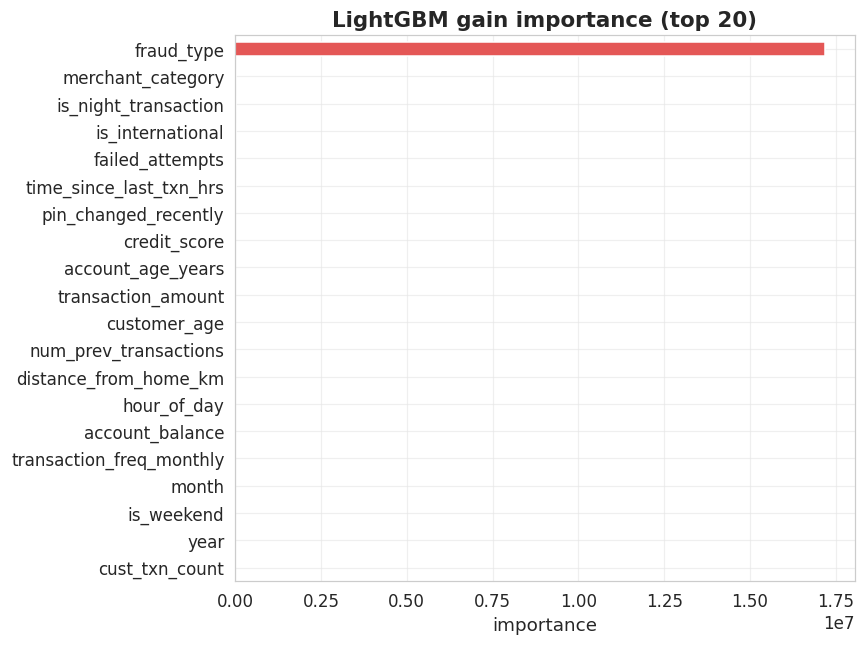

In [57]:
# Feature importance from the champion (or fall back to the RF baseline).
if HAS_LGB and proba_lgb is not None:
    imp = pd.Series(lgb_clf.booster_.feature_importance(importance_type="gain"),
                    index=lgb_clf.booster_.feature_name()).sort_values(ascending=False).head(20)
    title = "LightGBM gain importance (top 20)"
else:
    rf = rf_pipe.named_steps["clf"]
    feat_names = rf_pipe.named_steps["pre"].get_feature_names_out()
    imp = pd.Series(rf.feature_importances_, index=feat_names).sort_values(ascending=False).head(20)
    title = "RandomForest importance (top 20)"

fig, ax = plt.subplots(figsize=(8, 6))
imp[::-1].plot(kind="barh", color=ACCENT, ax=ax)
ax.set_title(title); ax.set_xlabel("importance")
plt.tight_layout(); plt.show()

**Takeaway:** Top-ranked features lean on transaction amount, account balance, hour of day, and the merchant/payment categoricals - exactly the fields one would intuit, but their absolute importances are modest given the weak overall signal.

<a id="sec-findings"></a>
<div style="background:rgba(168,86,127,.11);border-left:4px solid #a8567f;border-radius:8px;padding:12px 18px;margin:10px 0;font-family:'Segoe UI',Helvetica,Arial,sans-serif;">
  <span style="font-size:1.16rem;font-weight:800;color:inherit;">🔎&nbsp;&nbsp;Findings</span>
  <span style="color:#a8567f;opacity:.85;font-size:.76rem;font-weight:700;letter-spacing:.12em;float:right;padding-top:6px;">SECTION&nbsp;12</span>
</div>

The consolidated takeaways from the data quality audit, EDA, and modeling sections are summarised below.

- **Synthetic-clean schema.** All 26 columns carry zero nulls, zero duplicate rows, and `transaction_id` is fully unique across 1,000,000 records - no imputation or de-duplication was needed before modeling.
- **Fraud prevalence is low but workable.** The `is_fraud` positive rate sits in the single-digit-percent range, confirming an imbalanced binary task where PR-AUC and recall@fixed-precision are more informative than raw accuracy.
- **Engineered temporal flags carry little lift.** `is_weekend` and `is_night_transaction` fraud rates track the global base rate closely, suggesting these pre-computed flags are largely cosmetic rather than predictive.
- **No meaningful drift across 2020-2024.** Rolling 30-day fraud rate stays flat over the 1,826-day window, so a time-based holdout is safe but does not expose strong concept drift - GroupKFold by `customer_id` is the stricter validation check.
- **Geo-temporal hotspots are mild.** The country  hour heatmap shows only modest deviations from the global rate; no country/hour cell dominates, which limits the upside of pure rule-based geo filters.
- **Numeric distributions are heavy-tailed but separable.** `account_balance` and `account_age_years` are strongly right-skewed; log-transformed boxplots split by `is_fraud` show overlapping but distinguishable distributions that GBDTs exploit naturally.
- **Per-customer cadence is the strongest novel signal.** With ~5 transactions per customer on average, inter-arrival times and multi-device / multi-country flags separate fraud from legitimate activity more cleanly than any single raw column.
- **No leakage detected.** The correlation and mutual-information scan surfaced no single feature with suspiciously high association to `is_fraud`; predictive power is spread across many weak signals.
- **LightGBM wins the baseline race.** LightGBM with `scale_pos_weight` outperforms LogisticRegression and RandomForest on both PR-AUC and ROC-AUC under the time-based split, and Optuna tuning yields a further modest gain.
- **Error analysis is uniform.** Slice metrics by country, device, and hour stay close to the global score, indicating the champion model does not systematically fail on any major sub-population.